<a href="https://www.kaggle.com/code/lalit7881/air-quality-eda-73?scriptVersionId=360259571" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/srisyra02/air-quality-dataset/air_quality_dataset.csv


## Loading dataset

In [2]:
df= pd.read_csv("/kaggle/input/datasets/srisyra02/air-quality-dataset/air_quality_dataset.csv")

In [3]:
df.head()

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
0,39.967142,57.926035,116.192213,55.230299,4.531693,75.317261,2.789606,427.674347,1.706105,31.085120
1,101.935672,150.774299,76.826826,79.051618,18.744780,145.083987,1.966569,529.739619,2.492663,33.711103
2,70.996192,138.948796,158.731020,60.466604,14.892239,145.147338,2.626446,499.889443,2.431165,33.778698
3,28.464728,63.643900,25.385343,15.333286,7.647429,130.022319,1.779360,388.283712,1.818563,31.565877
4,78.265276,113.977926,105.644340,59.202337,17.696806,181.713667,3.240533,464.739197,2.597225,32.229835


In [4]:
df.tail()

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
495,51.380025,57.573550,31.124630,19.276010,11.167098,104.071502,1.844483,397.418878,1.923525,34.323410
496,46.816837,75.372133,22.174014,18.535162,12.169426,74.802208,1.364096,392.316075,2.157281,26.321361
497,33.909351,88.097250,27.630317,15.653370,7.997326,128.105470,2.319453,378.653347,1.809489,28.964494
498,43.721651,40.847991,27.253977,19.365916,7.218154,106.053329,1.599748,389.878566,1.858964,29.976442
499,43.135587,34.287210,4.290139,5.122962,7.415822,93.332250,1.633200,388.029985,2.059903,26.649351


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PM2.5        500 non-null    float64
 1   PM10         500 non-null    float64
 2   NOx          500 non-null    float64
 3   NO2          500 non-null    float64
 4   SO2          500 non-null    float64
 5   VOCs         500 non-null    float64
 6   CO           500 non-null    float64
 7   CO2          500 non-null    float64
 8   CH4          500 non-null    float64
 9   Temperature  500 non-null    float64
dtypes: float64(10)
memory usage: 39.2 KB


In [6]:
df.describe()

,PM2.5,PM10,NOx,NO2,SO2,VOCs,CO,CO2,CH4,Temperature
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,54.671620,84.703251,91.814080,42.410820,11.504816,112.193098,2.177705,439.288087,2.130439,30.448413
std,22.799473,30.567912,54.808414,26.343669,7.306978,39.471686,0.824762,51.220578,0.391396,2.957290
min,10.757597,12.932337,-0.076323,-1.942140,-1.095555,27.555617,0.366992,366.063158,1.388407,19.581349
25%,36.372940,61.118607,35.457263,17.448632,5.976492,81.516729,1.536915,397.399610,1.837395,28.481974
50%,48.038599,78.135558,95.452284,39.211583,8.681222,104.819124,2.045519,420.934319,2.066709,30.432756
75%,73.820566,110.270086,134.709240,63.817763,17.116673,140.588100,2.726020,490.968315,2.386267,32.614954
max,127.616632,171.594187,225.886935,115.916428,31.941860,231.926017,4.798935,558.924256,3.352266,39.778713


In [7]:
df.isnull().sum()

PM2.5          0
PM10           0
NOx            0
NO2            0
SO2            0
VOCs           0
CO             0
CO2            0
CH4            0
Temperature    0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.dtypes

PM2.5          float64
PM10           float64
NOx            float64
NO2            float64
SO2            float64
VOCs           float64
CO             float64
CO2            float64
CH4            float64
Temperature    float64
dtype: object

In [10]:
df.shape

(500, 10)

In [11]:
df.nunique()

PM2.5          500
PM10           500
NOx            500
NO2            500
SO2            500
VOCs           500
CO             500
CO2            500
CH4            500
Temperature    500
dtype: int64

In [12]:
df.columns

Index(['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4',
       'Temperature'],
      dtype='object')

## EDA

AIR QUALITY DATA VISUALIZATION
Dataset shape: (500, 10)
Columns: ['PM2.5', 'PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']

Missing values:


,Missing Values
PM2.5,0
PM10,0
NOx,0
NO2,0
SO2,0
VOCs,0
CO,0
CO2,0
CH4,0
Temperature,0



Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
PM2.5,500.0,54.67,22.80,10.76,36.37,48.04,73.82,127.62
PM10,500.0,84.70,30.57,12.93,61.12,78.14,110.27,171.59
NOx,500.0,91.81,54.81,-0.08,35.46,95.45,134.71,225.89
NO2,500.0,42.41,26.34,-1.94,17.45,39.21,63.82,115.92
SO2,500.0,11.50,7.31,-1.10,5.98,8.68,17.12,31.94
VOCs,500.0,112.19,39.47,27.56,81.52,104.82,140.59,231.93
CO,500.0,2.18,0.82,0.37,1.54,2.05,2.73,4.80
CO2,500.0,439.29,51.22,366.06,397.40,420.93,490.97,558.92
CH4,500.0,2.13,0.39,1.39,1.84,2.07,2.39,3.35
Temperature,500.0,30.45,2.96,19.58,28.48,30.43,32.61,39.78


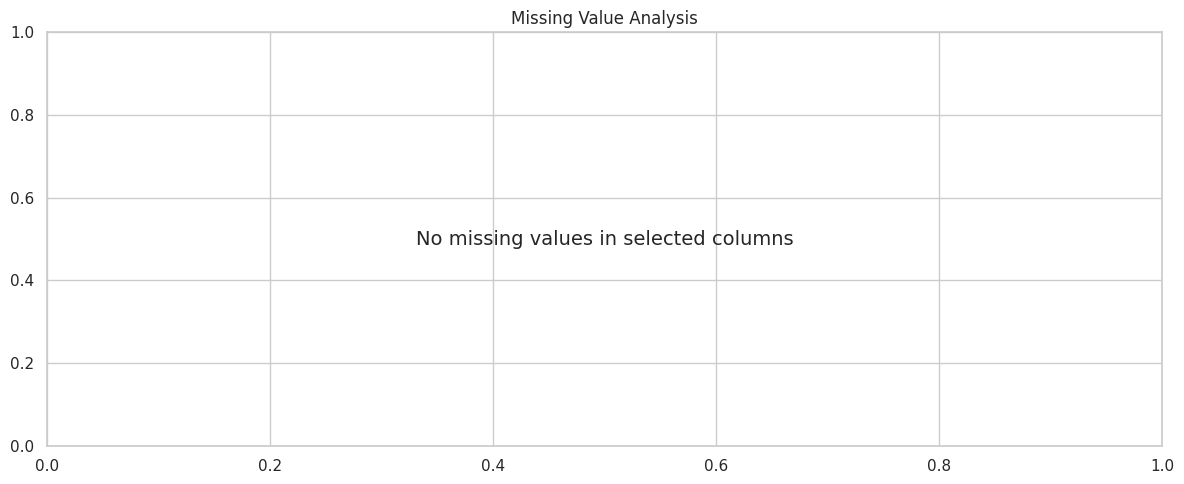

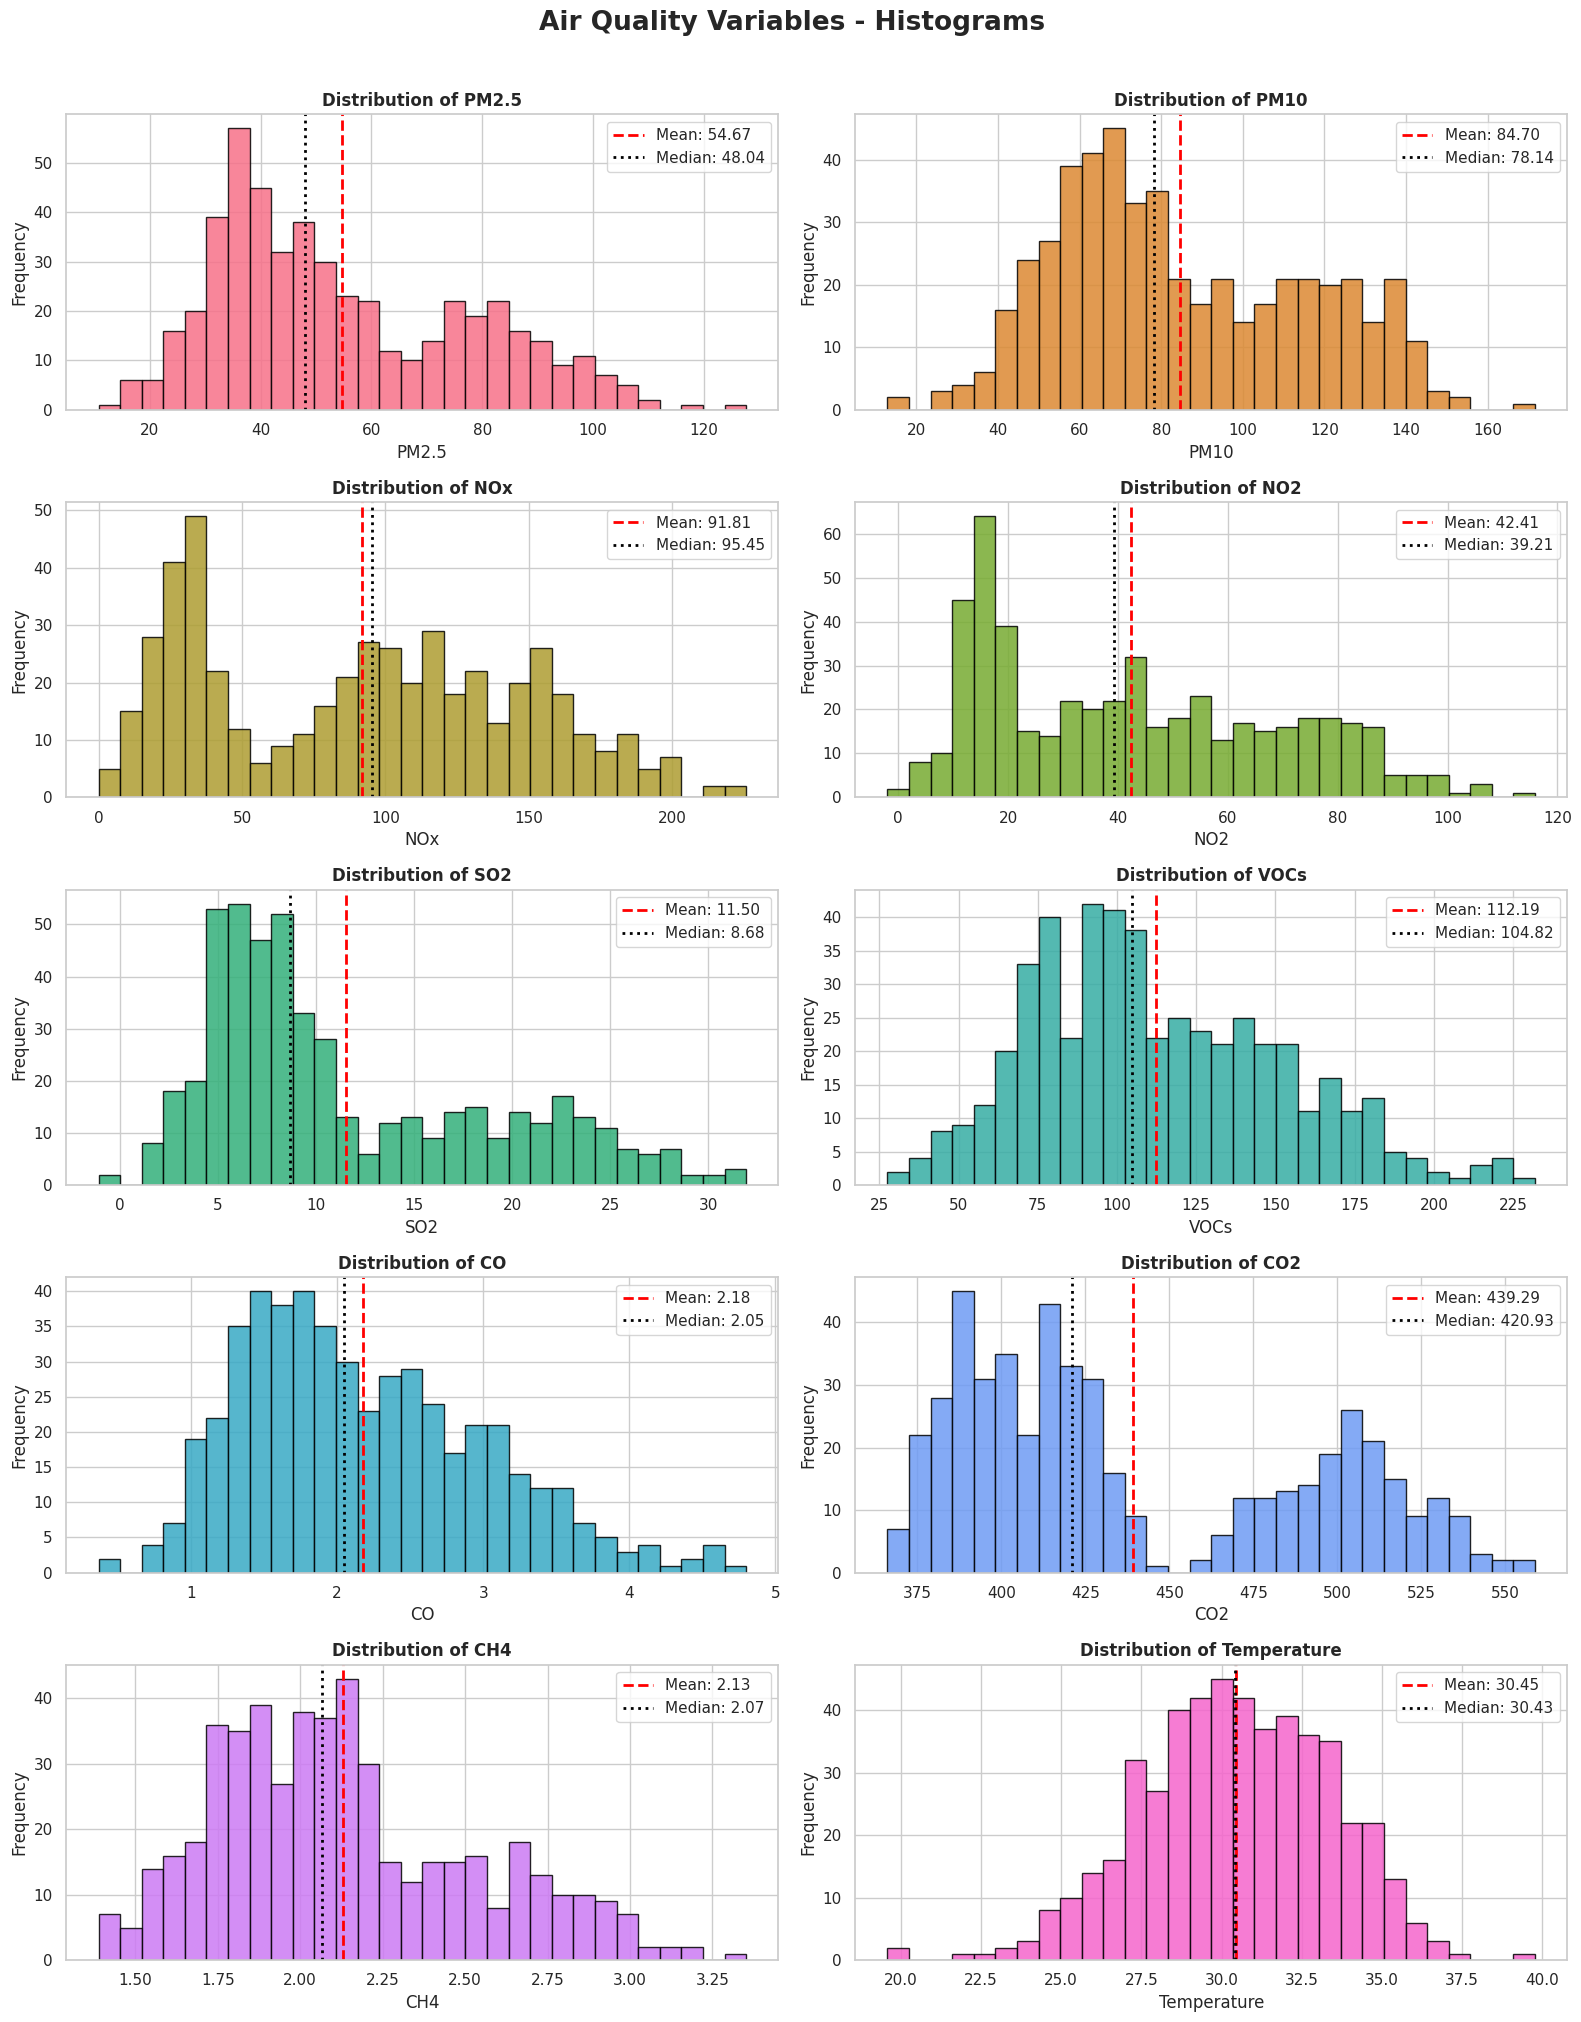

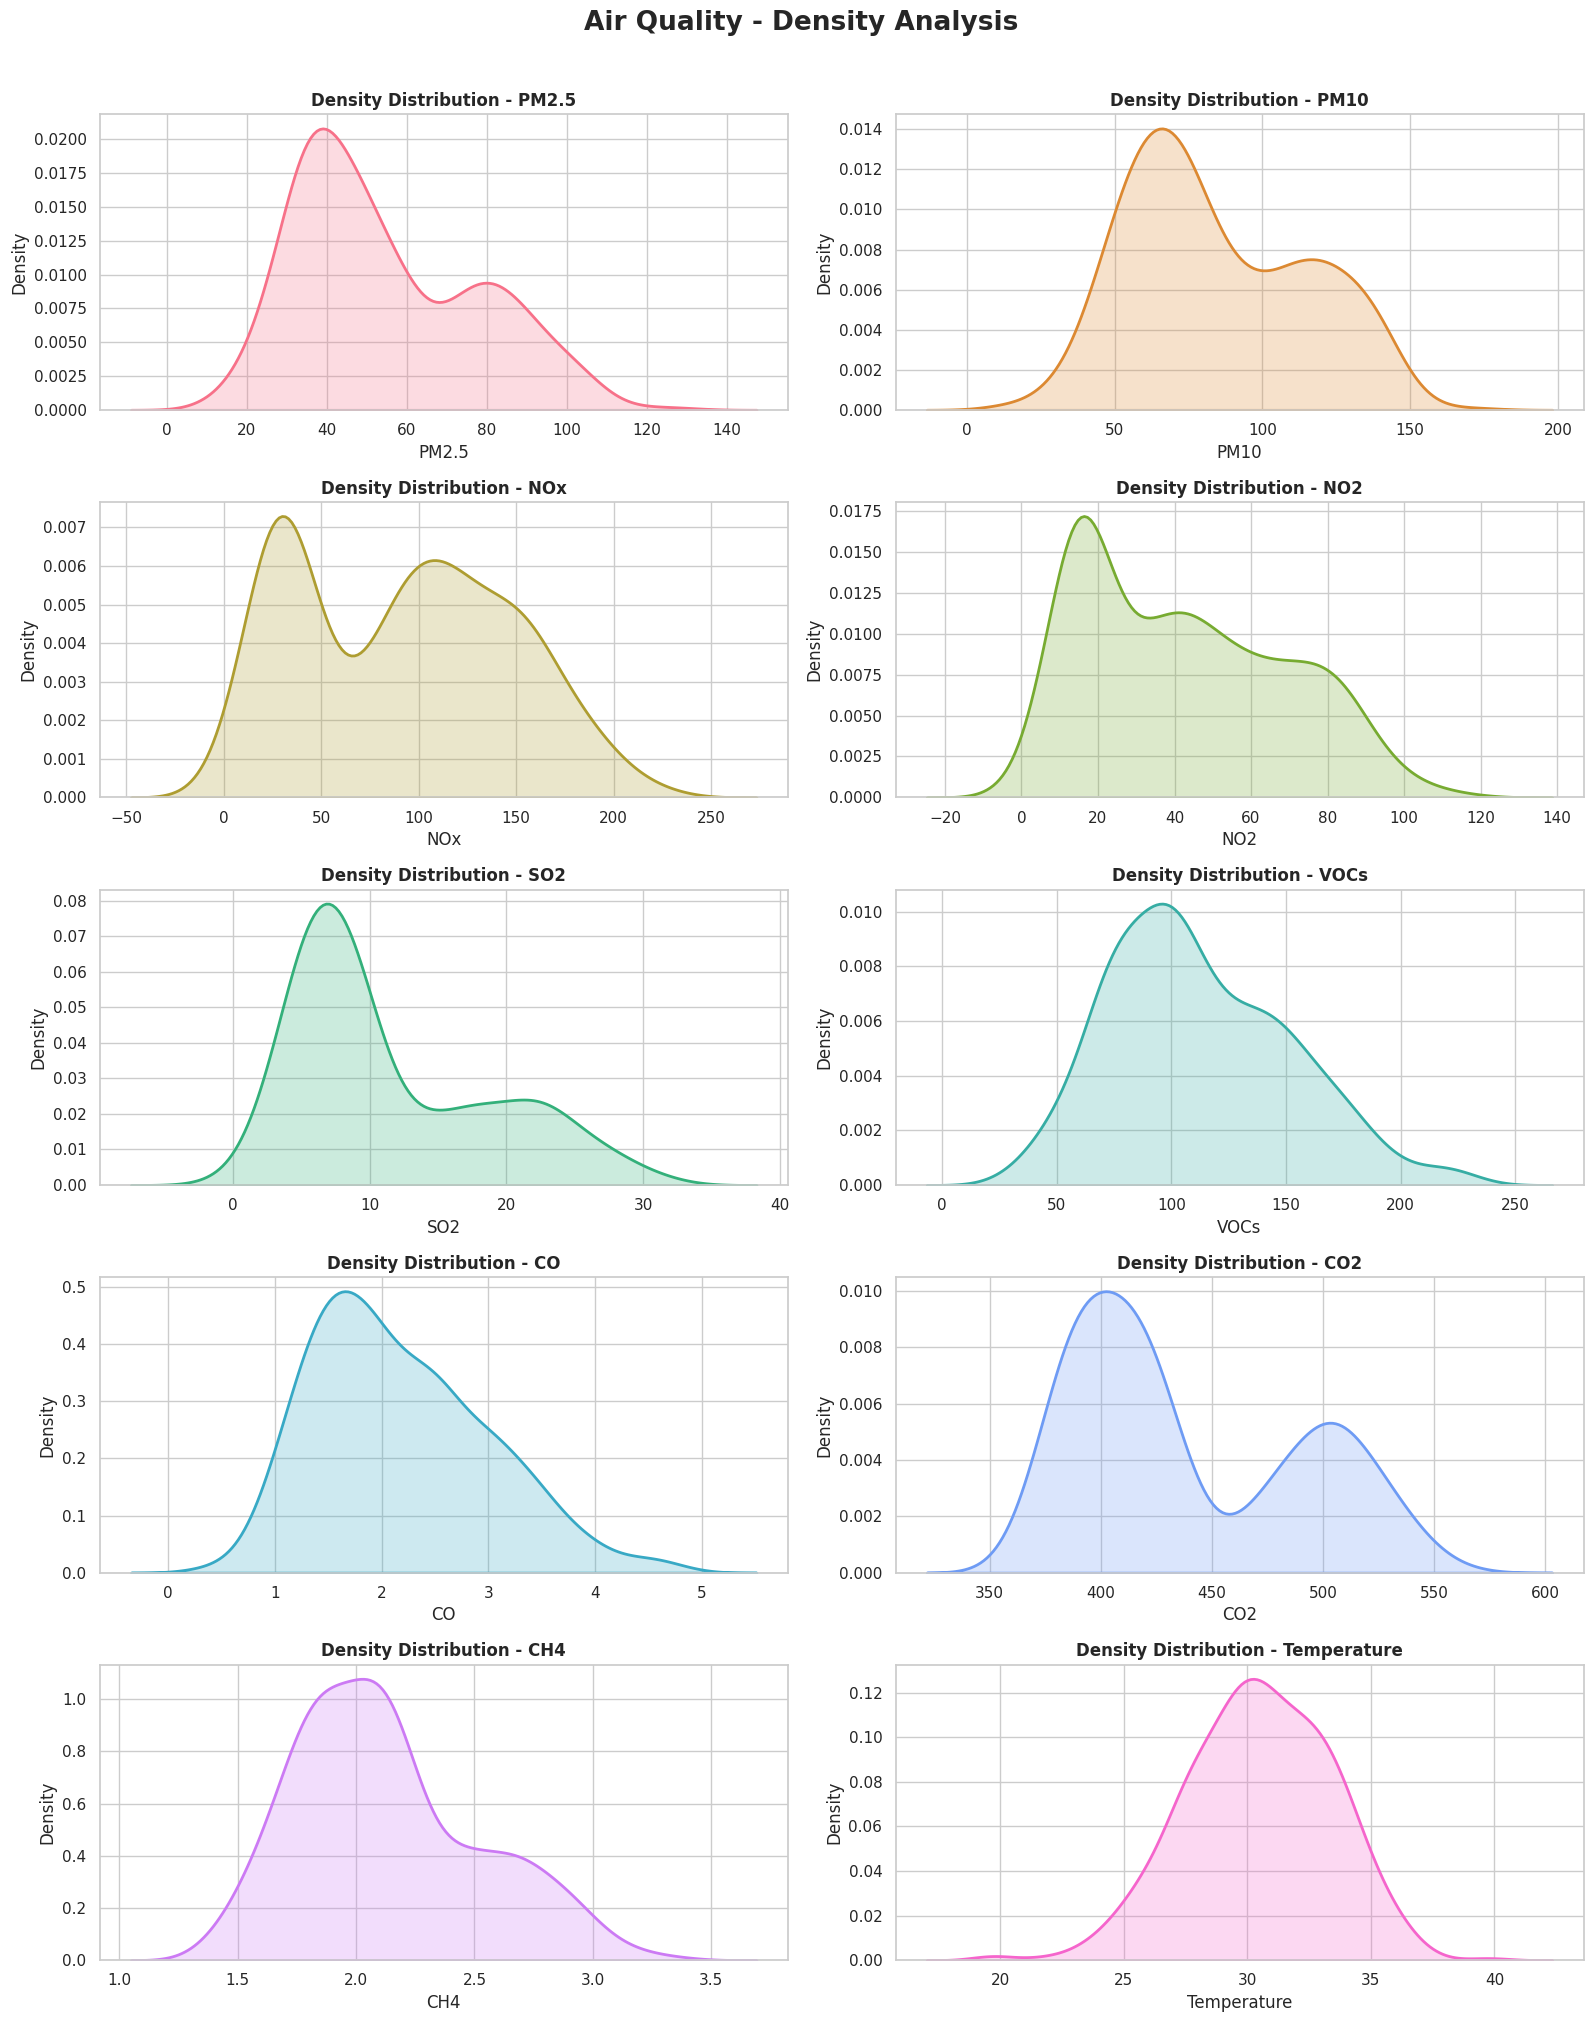

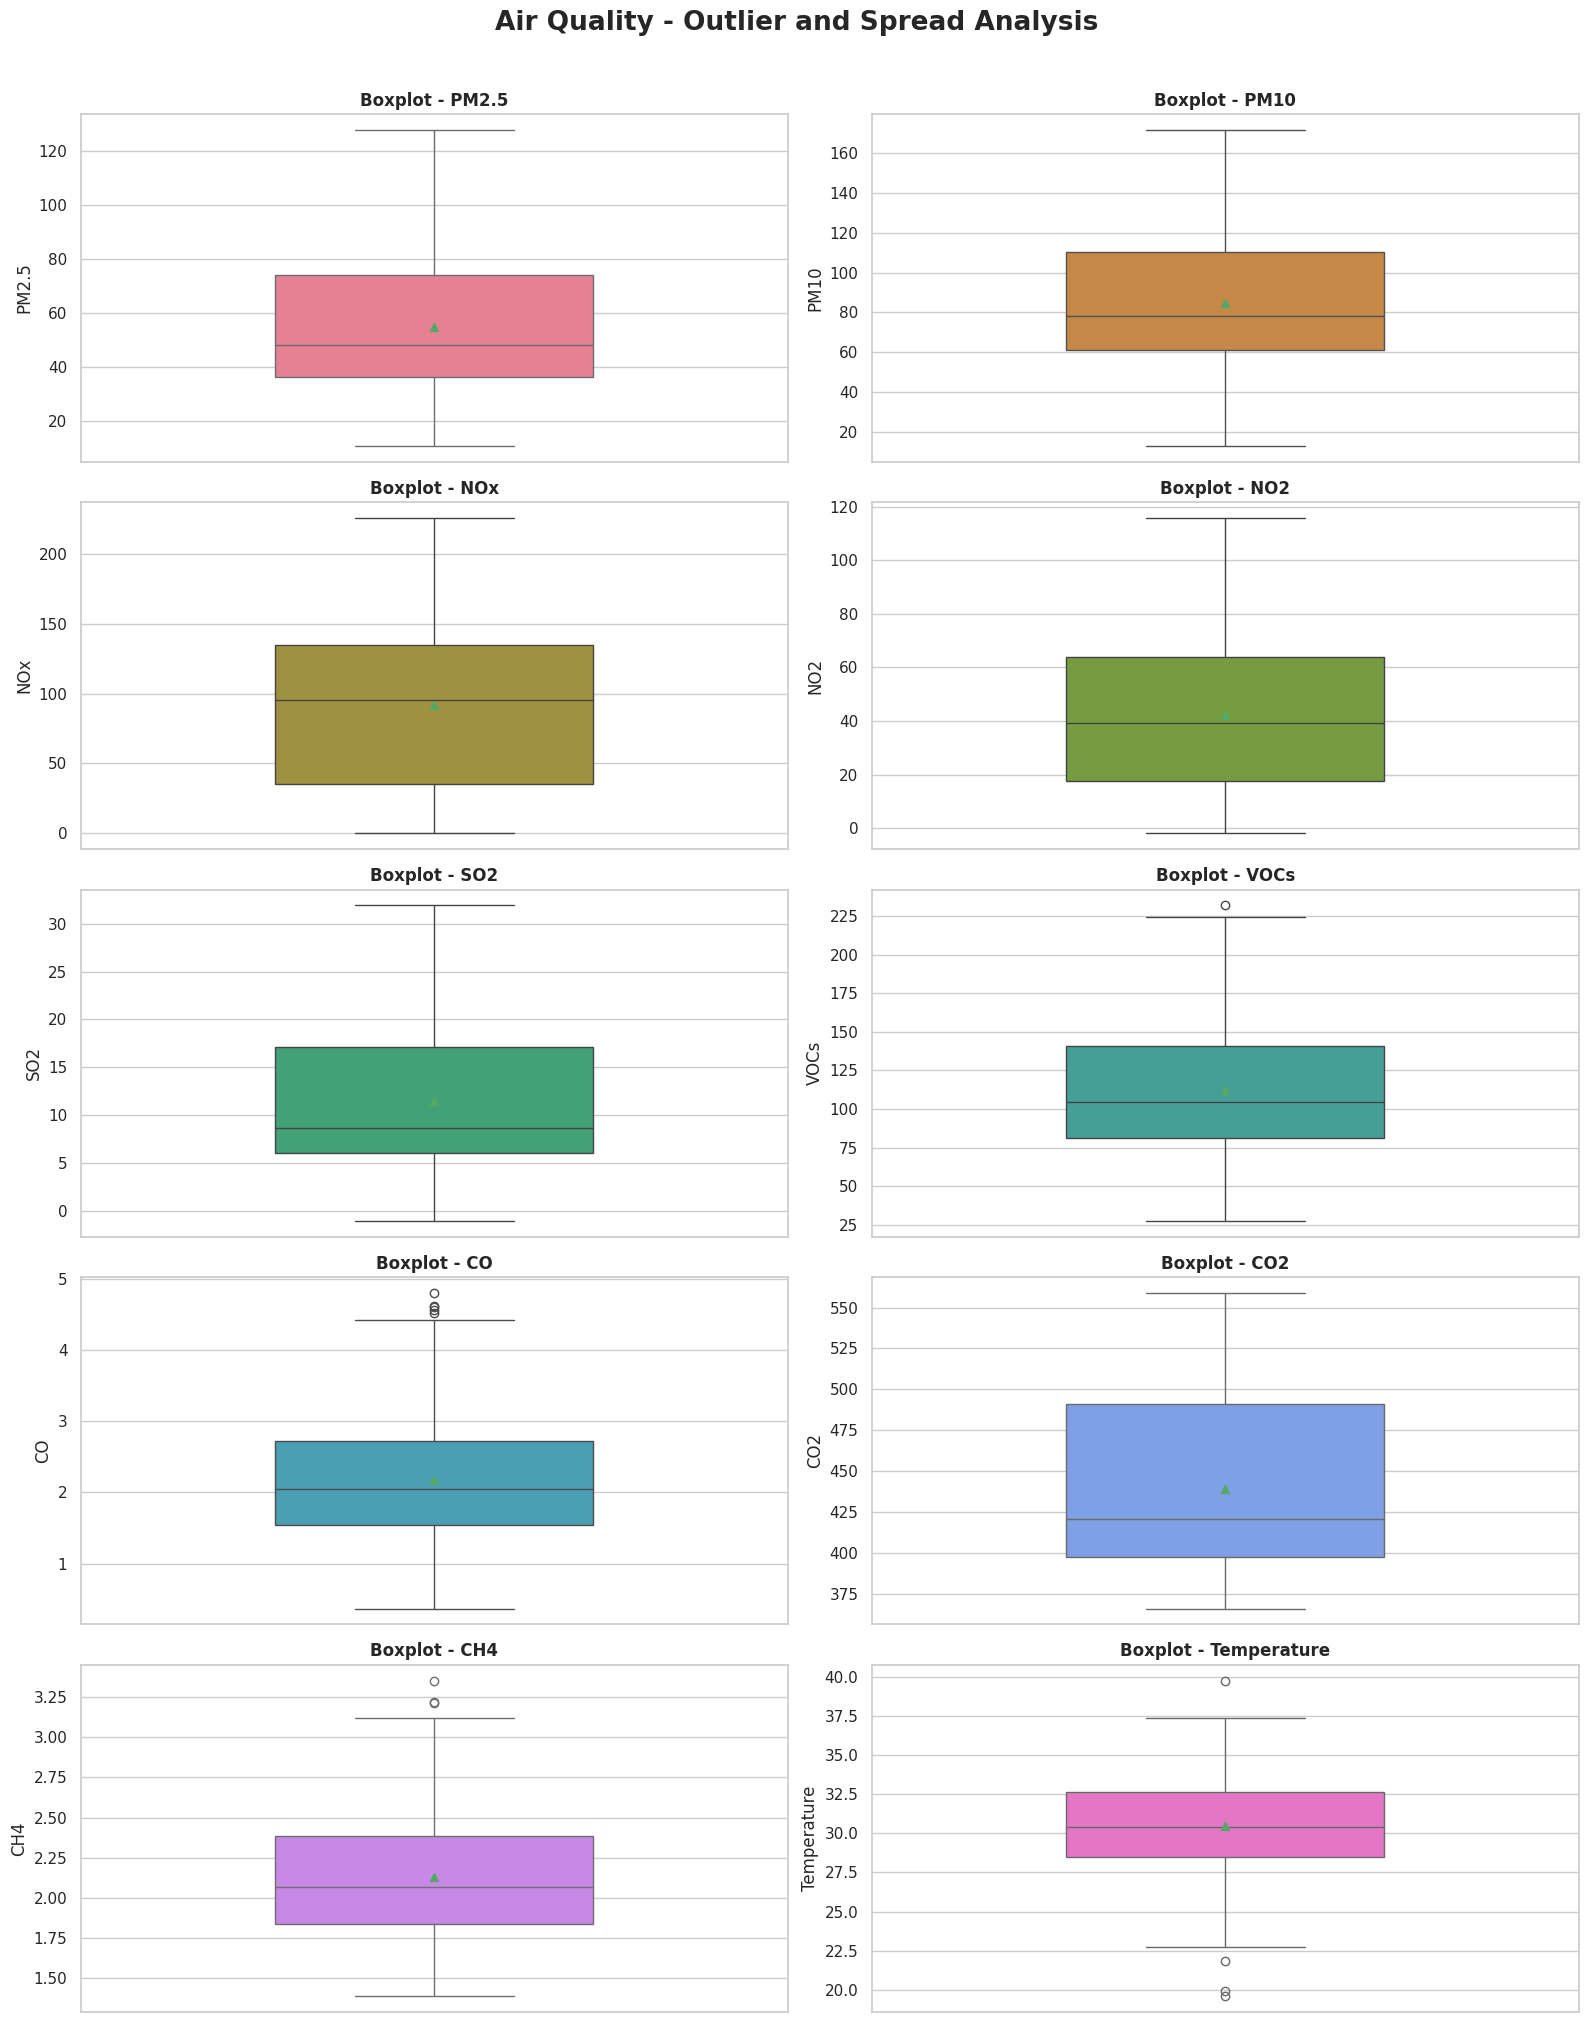

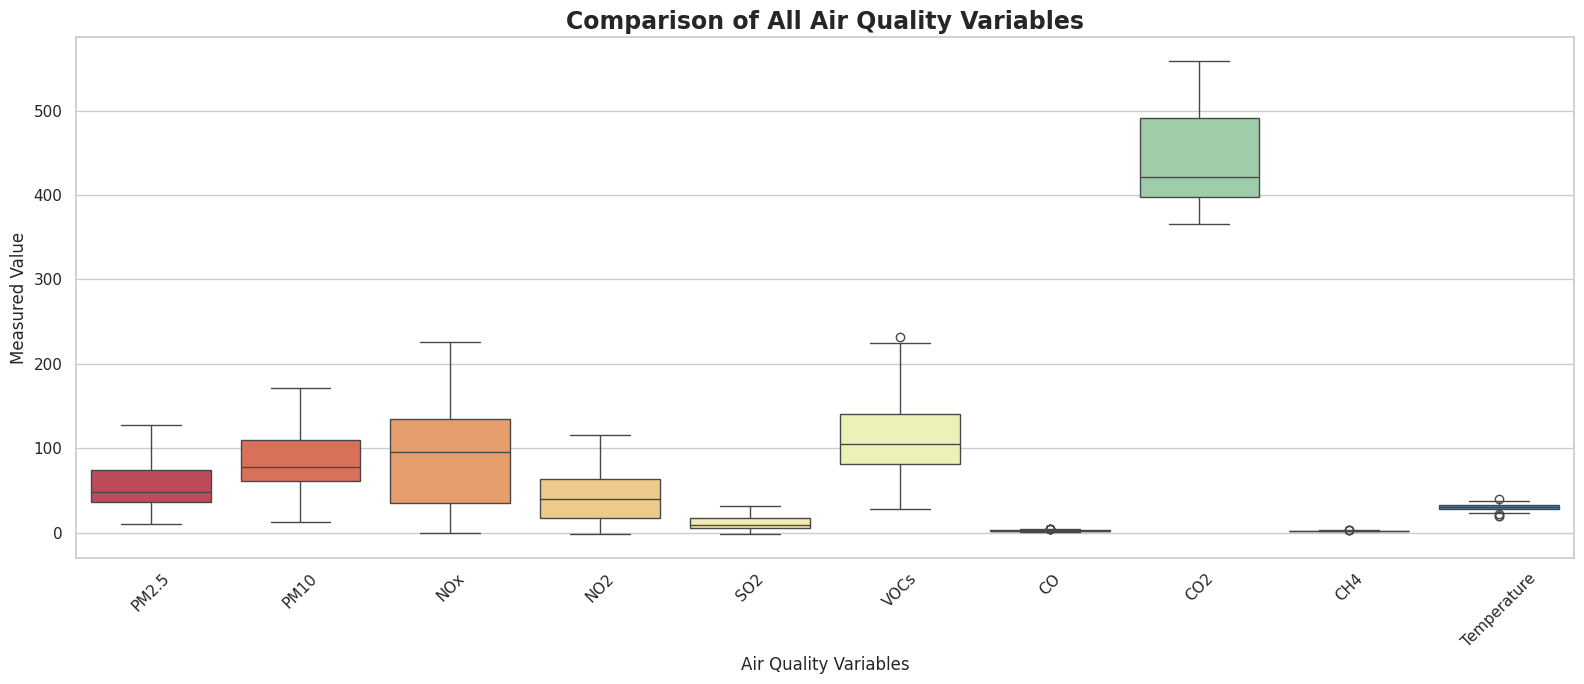

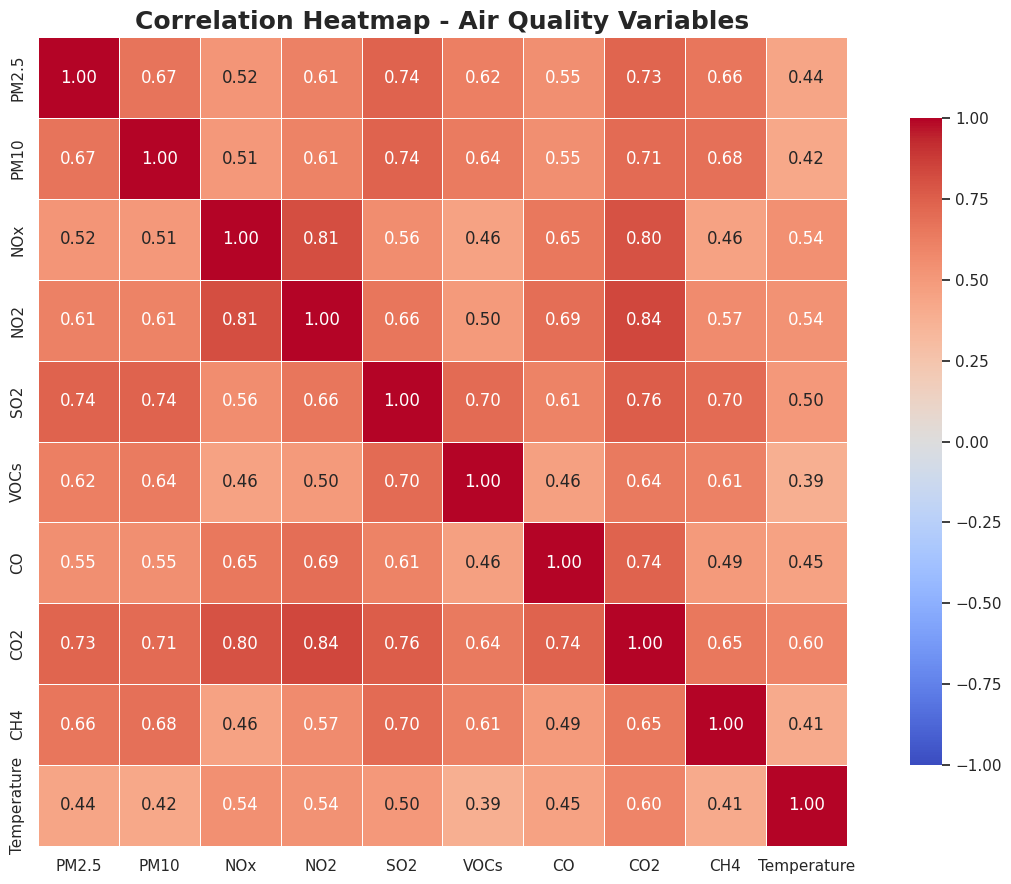

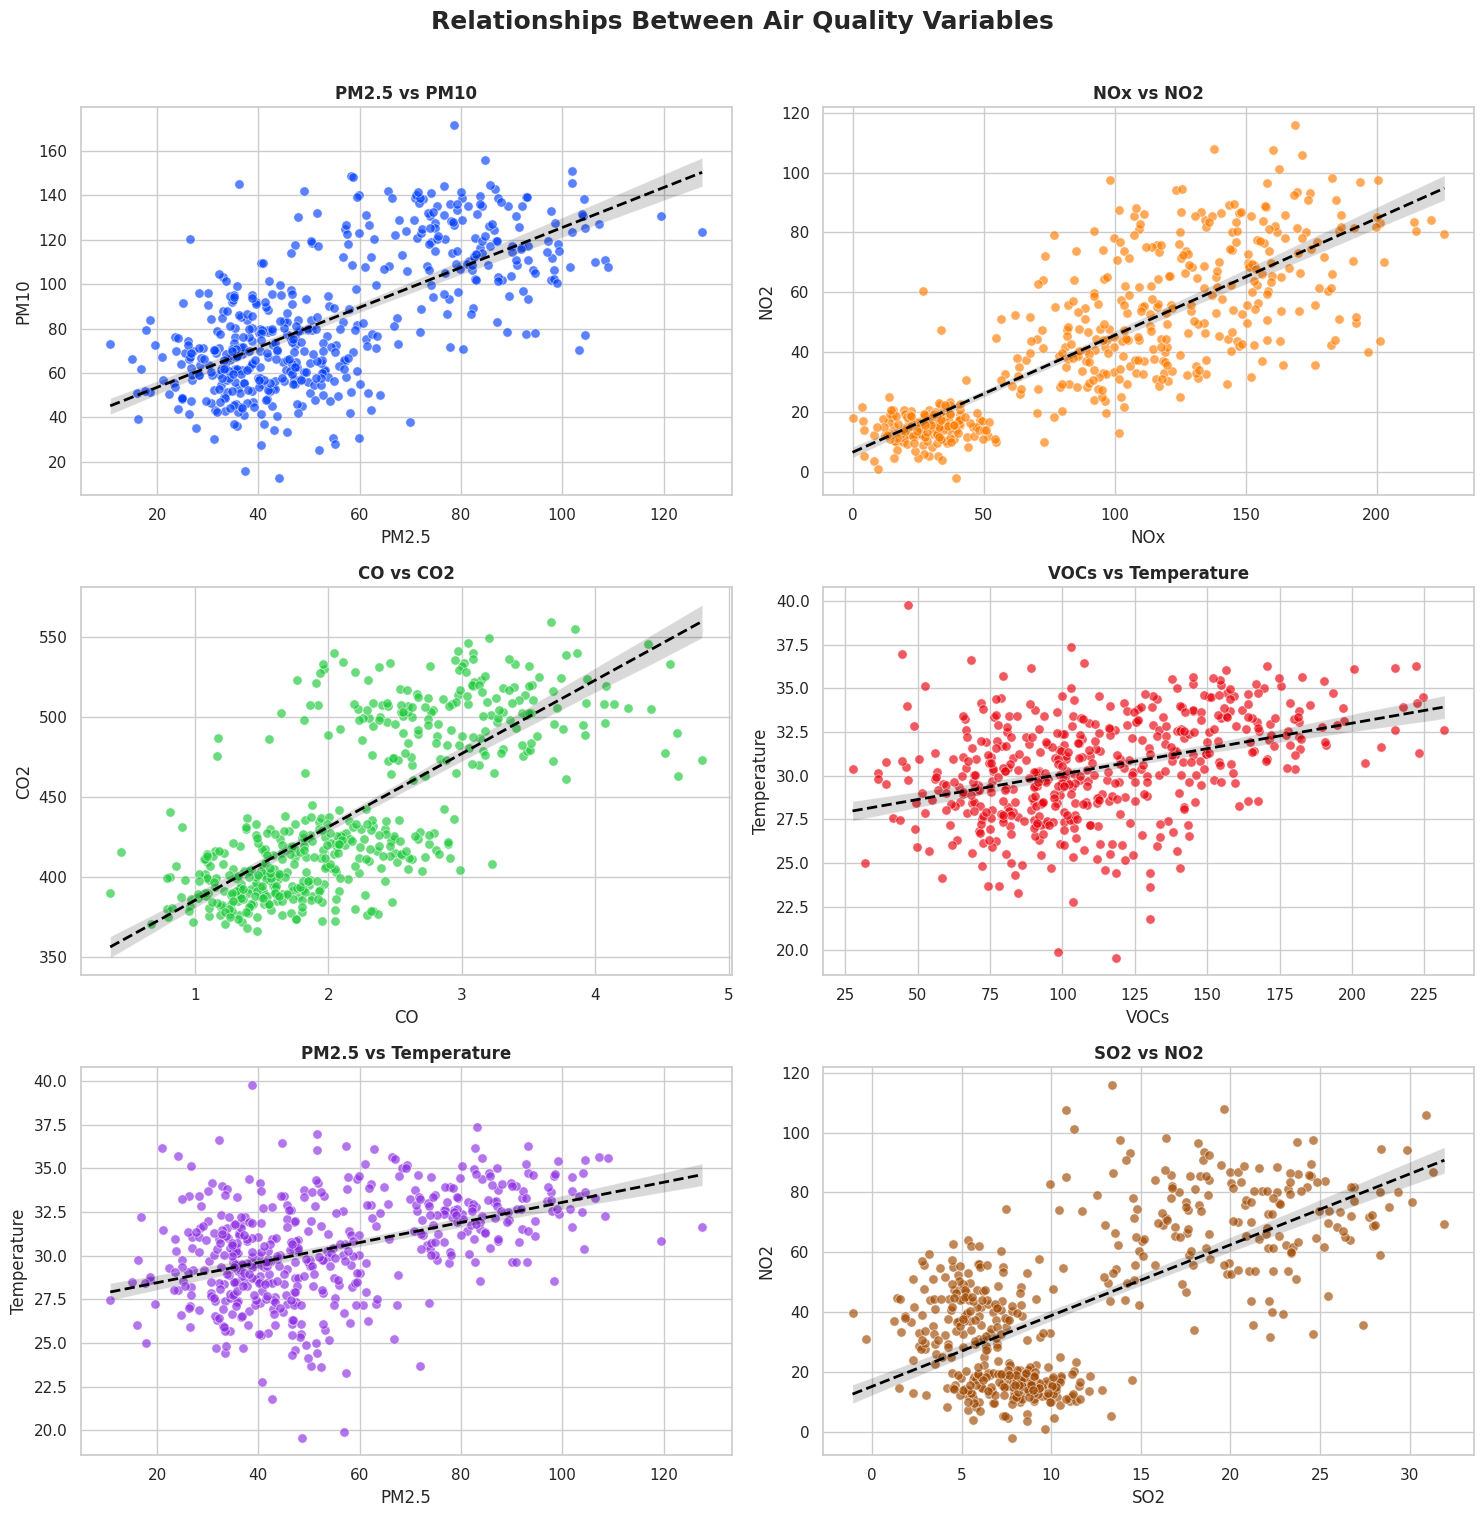

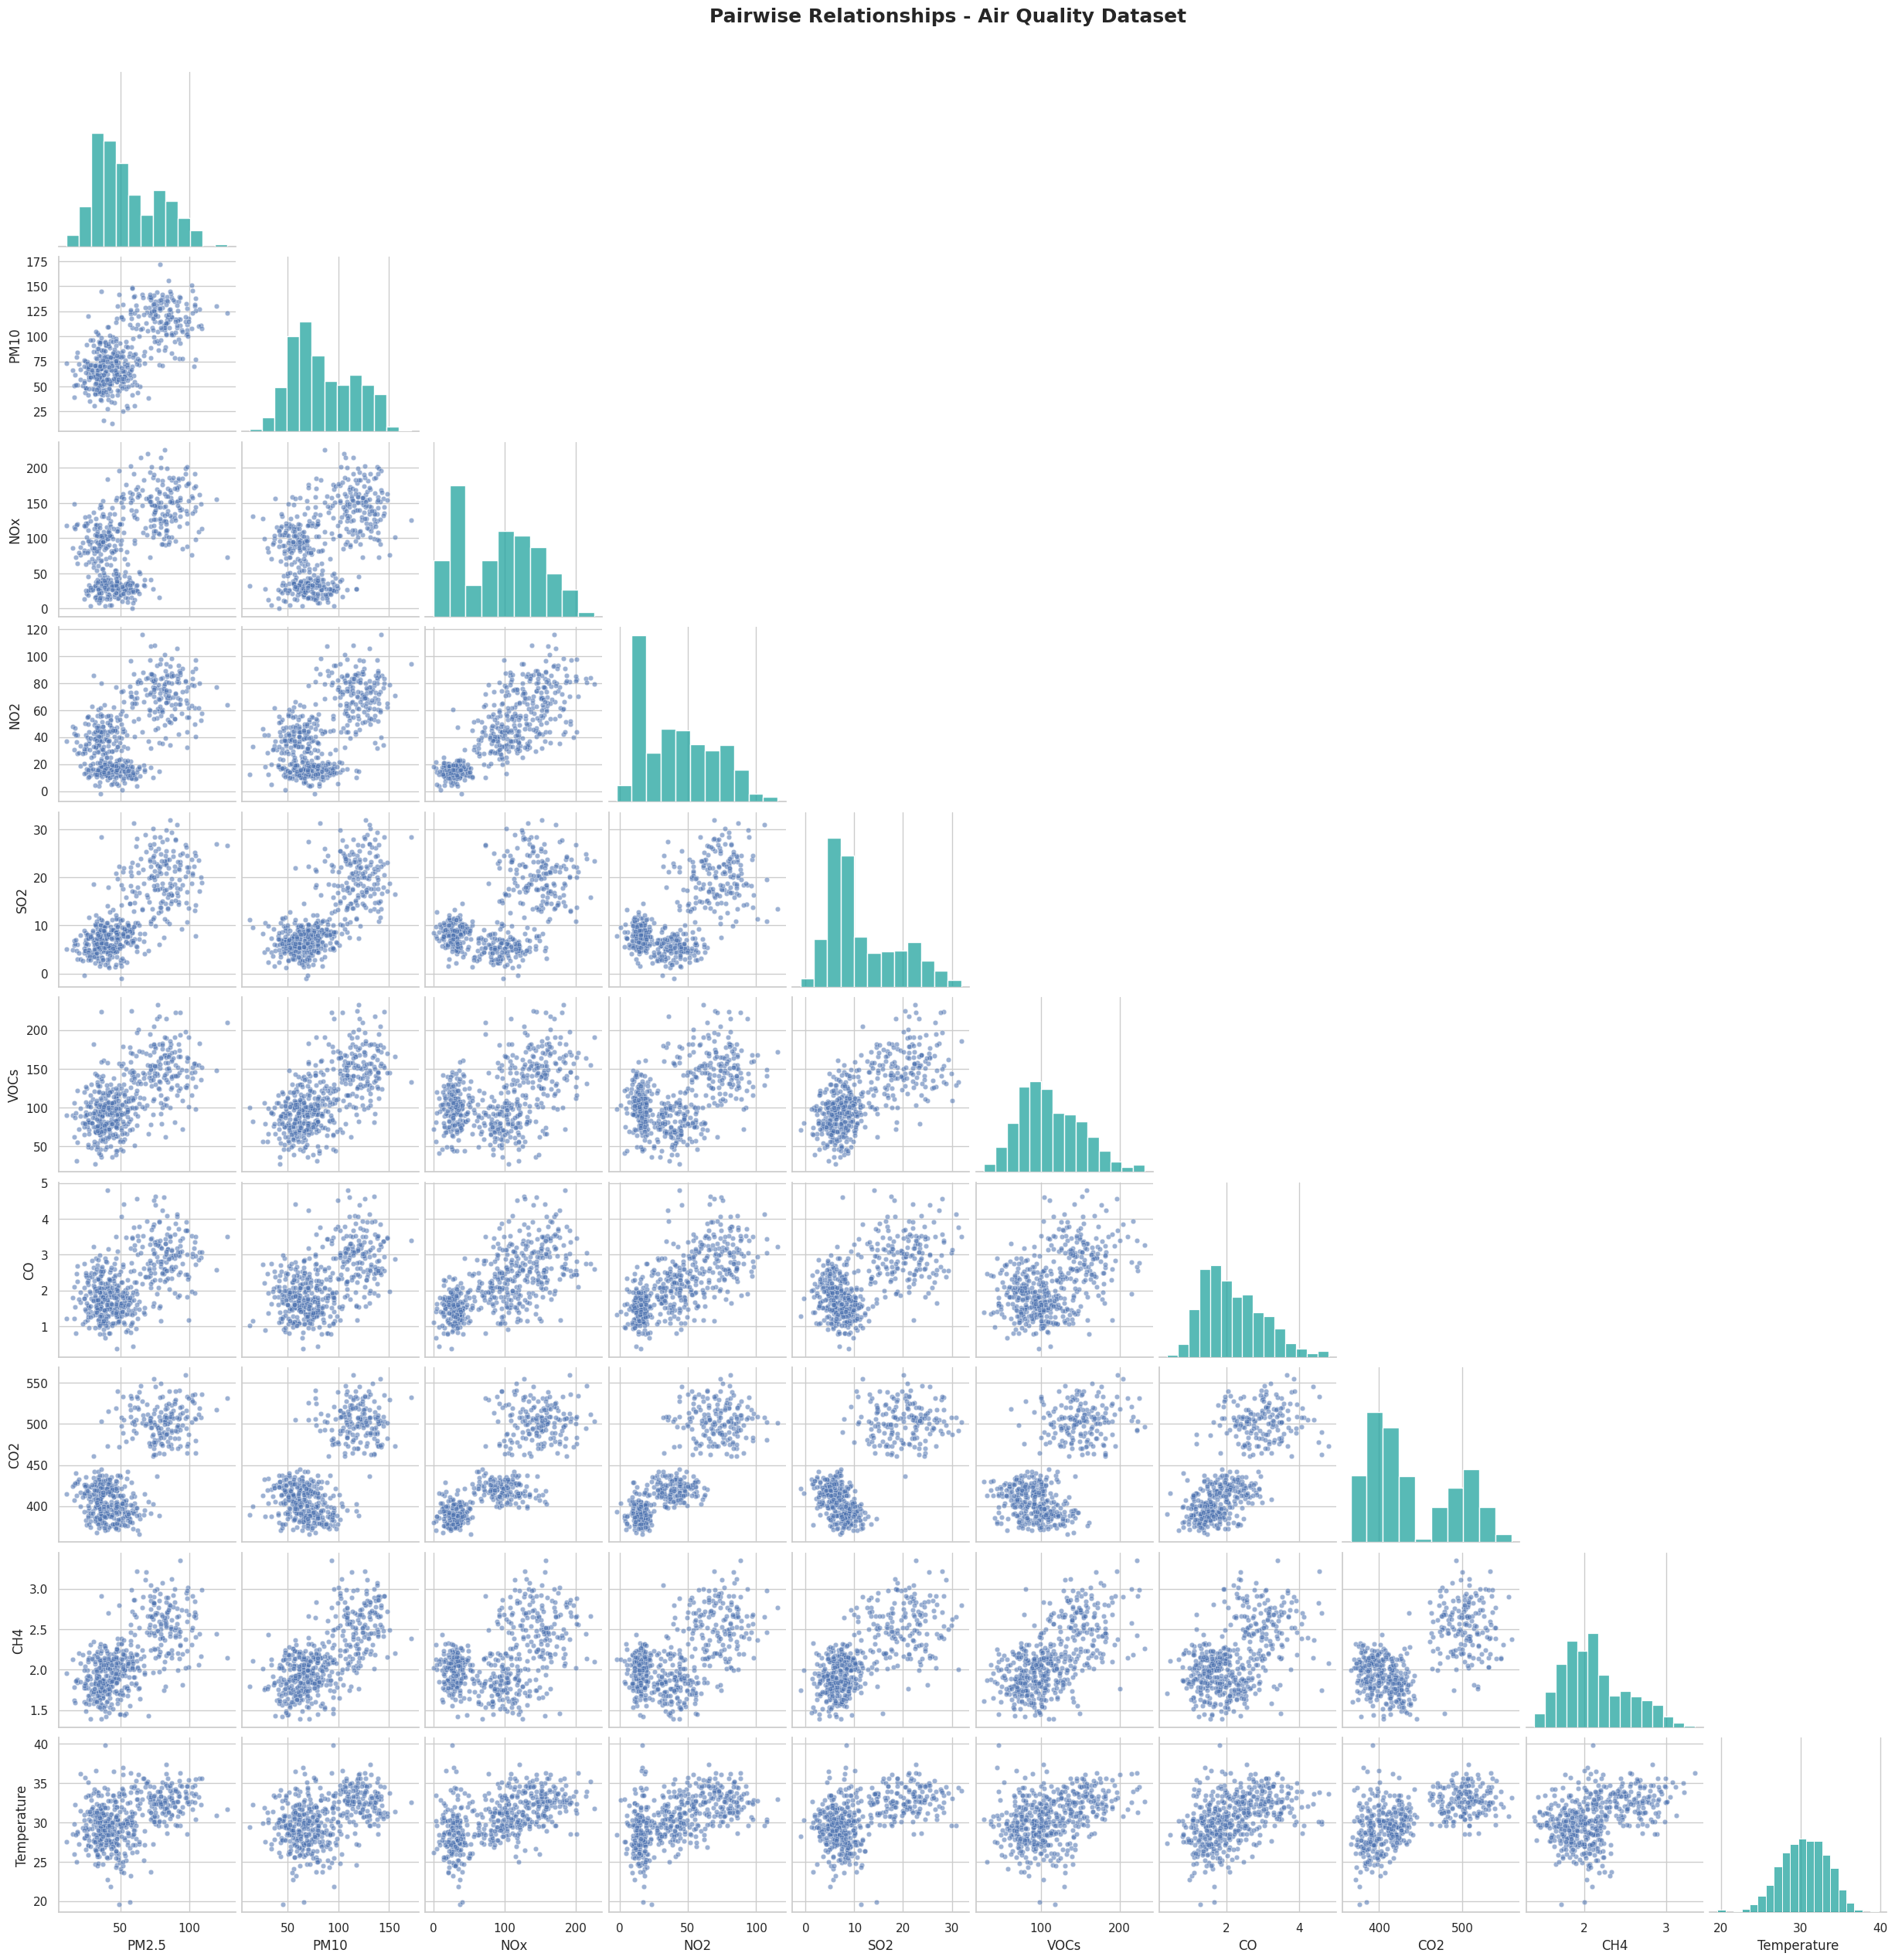

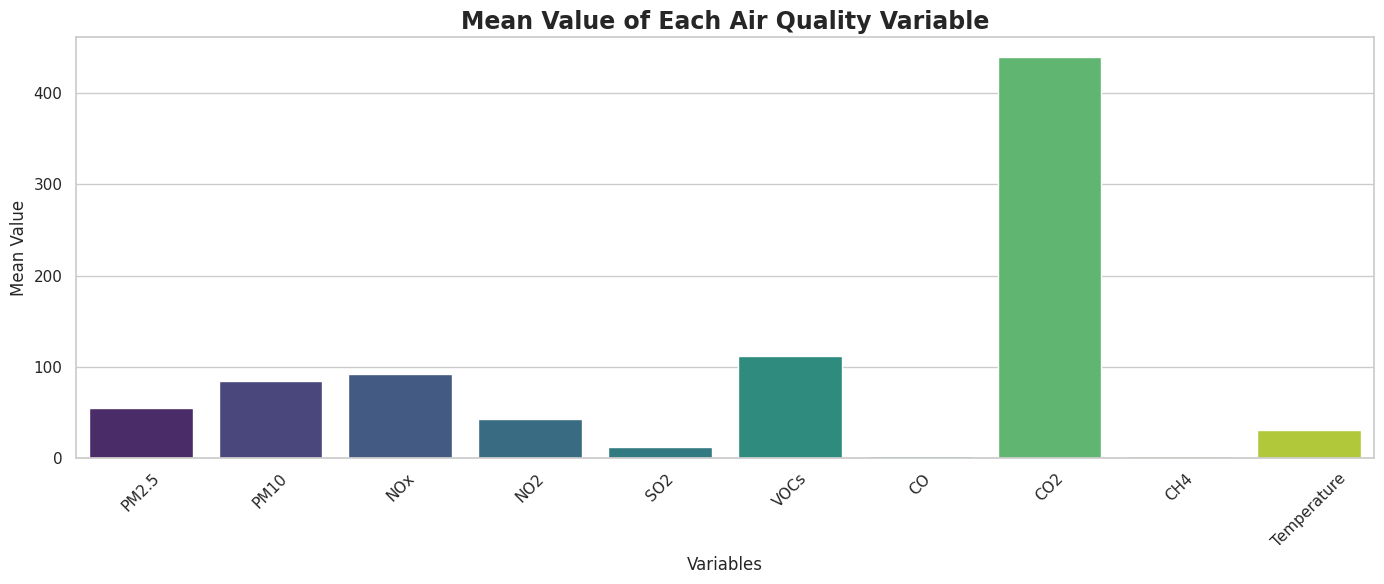

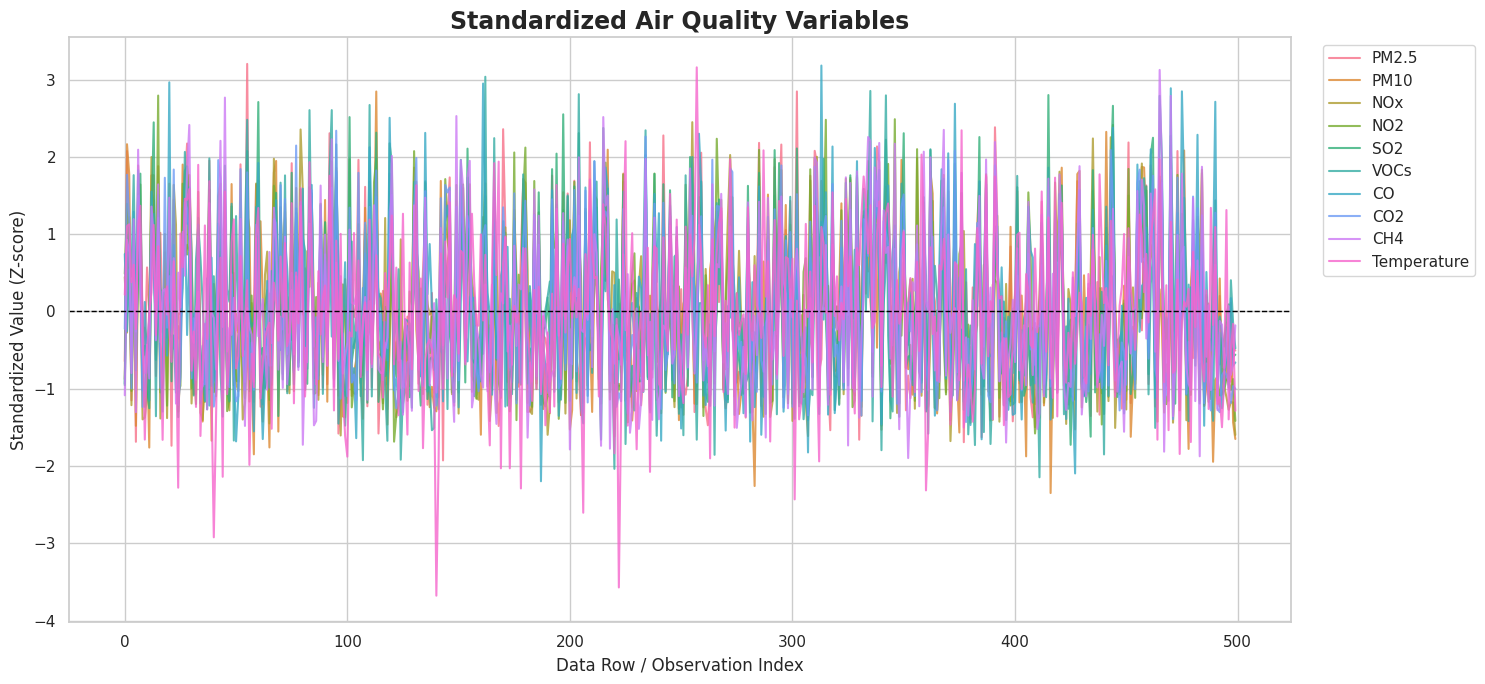


OUTLIER ANALYSIS


,Variable,Outlier Count,Outlier Percentage,Lower Bound,Upper Bound
0,PM2.5,0,0.0,-19.799,129.992
1,PM10,0,0.0,-12.609,183.997
2,NOx,0,0.0,-113.421,283.587
3,NO2,0,0.0,-52.105,133.371
4,SO2,0,0.0,-10.734,33.827
5,VOCs,1,0.2,-7.090,229.195
6,CO,5,1.0,-0.247,4.510
7,CO2,0,0.0,257.047,631.321
8,CH4,3,0.6,1.014,3.210
9,Temperature,4,0.8,22.283,38.814


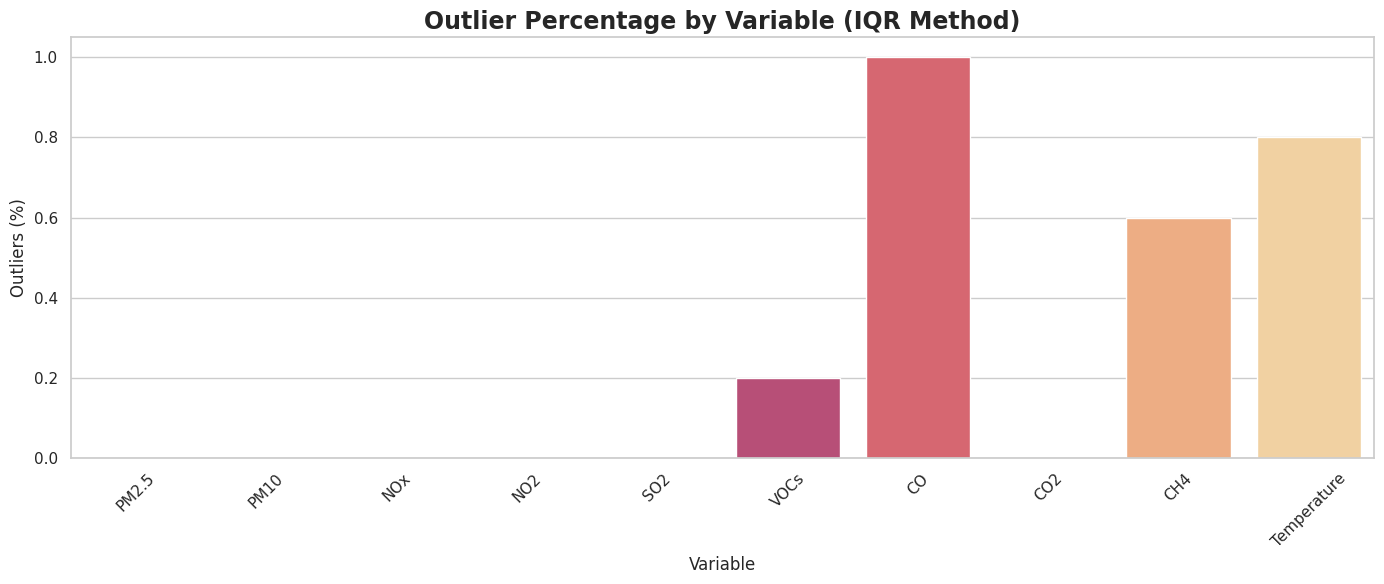

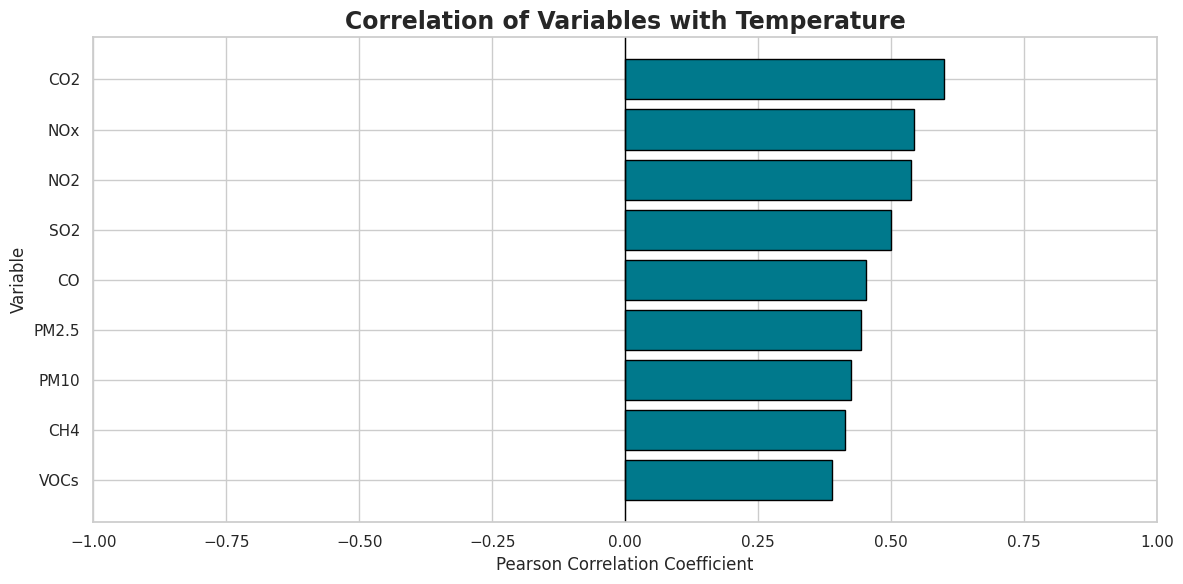


VISUALIZATION COMPLETED SUCCESSFULLY
Rows analyzed: 500
Variables analyzed: 10
Variables: PM2.5, PM10, NOx, NO2, SO2, VOCs, CO, CO2, CH4, Temperature

All requested visualizations have been generated.


In [13]:
from pandas.api.types import is_numeric_dtype
from IPython.display import display

# -------------------- 1. CONFIGURATION ---------------------------

sns.set_theme(style="whitegrid", context="notebook")

# Your specified columns
columns = [
    'PM2.5', 'PM10', 'NOx', 'NO2', 'SO2',
    'VOCs', 'CO', 'CO2', 'CH4', 'Temperature'
]

# Check whether df exists
if 'df' not in globals():
    raise NameError("Please load your dataset into a DataFrame named 'df'.")

# Keep only available columns
available_columns = [col for col in columns if col in df.columns]

if not available_columns:
    raise ValueError(
        "None of the specified columns were found in df. "
        "Check your DataFrame column names."
    )

# Work on a copy
data = df[available_columns].copy()

# Convert selected columns to numeric
for col in available_columns:
    data[col] = pd.to_numeric(data[col], errors='coerce')

# Replace infinite values and remove rows where every selected value is missing
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna(how='all')

# Drop columns with no valid numeric values
data = data.dropna(axis=1, how='all')
available_columns = data.columns.tolist()

if data.empty or len(available_columns) == 0:
    raise ValueError("No valid numeric data found in the selected columns.")

print("=" * 70)
print("AIR QUALITY DATA VISUALIZATION")
print("=" * 70)
print("Dataset shape:", data.shape)
print("Columns:", available_columns)
print("\nMissing values:")
display(data.isnull().sum().to_frame("Missing Values"))

print("\nStatistical Summary:")
display(data.describe().T.round(2))

# -------------------- 2. COLOR PALETTE --------------------------

palette = sns.color_palette("husl", len(available_columns))
color_map = dict(zip(available_columns, palette))

# -------------------- 3. MISSING VALUE VISUALIZATION ------------

plt.figure(figsize=(12, 5))
missing = data.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

if len(missing) > 0:
    sns.barplot(
        x=missing.index,
        y=missing.values,
        hue=missing.index,
        palette="rocket",
        legend=False
    )
    plt.title("Missing Values by Air Quality Variable",
              fontsize=16, fontweight="bold")
    plt.xlabel("Variables")
    plt.ylabel("Missing Value Count")
    plt.xticks(rotation=45)
else:
    plt.text(0.5, 0.5, "No missing values in selected columns",
             ha="center", va="center", fontsize=14)
    plt.title("Missing Value Analysis")

plt.tight_layout()
plt.show()

# -------------------- 4. HISTOGRAMS -----------------------------

ncols = 2
nrows = int(np.ceil(len(available_columns) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 4 * nrows)
)
axes = np.array(axes).reshape(-1)

for i, col in enumerate(available_columns):
    values = data[col].dropna()

    axes[i].hist(
        values,
        bins=30,
        color=color_map[col],
        edgecolor="black",
        alpha=0.85
    )

    axes[i].axvline(
        values.mean(), color="red", linestyle="--",
        linewidth=2, label=f"Mean: {values.mean():.2f}"
    )

    axes[i].axvline(
        values.median(), color="black", linestyle=":",
        linewidth=2, label=f"Median: {values.median():.2f}"
    )

    axes[i].set_title(f"Distribution of {col}", fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")
    axes[i].legend()

for j in range(len(available_columns), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Air Quality Variables - Histograms",
             fontsize=19, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# -------------------- 5. KDE DISTRIBUTION PLOTS -----------------

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 4 * nrows)
)
axes = np.array(axes).reshape(-1)

for i, col in enumerate(available_columns):
    values = data[col].dropna()

    if len(values) > 1 and values.nunique() > 1:
        sns.kdeplot(
            x=values,
            fill=True,
            color=color_map[col],
            linewidth=2,
            ax=axes[i]
        )
    else:
        axes[i].text(
            0.5, 0.5, "Insufficient variation",
            ha="center", va="center",
            transform=axes[i].transAxes
        )

    axes[i].set_title(f"Density Distribution - {col}",
                      fontweight="bold")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Density")

for j in range(len(available_columns), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Air Quality - Density Analysis",
             fontsize=19, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# -------------------- 6. BOXPLOTS -------------------------------

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, 4 * nrows)
)
axes = np.array(axes).reshape(-1)

for i, col in enumerate(available_columns):
    sns.boxplot(
        y=data[col],
        color=color_map[col],
        width=0.45,
        showmeans=True,
        ax=axes[i]
    )

    axes[i].set_title(f"Boxplot - {col}", fontweight="bold")
    axes[i].set_ylabel(col)
    axes[i].set_xlabel("")

for j in range(len(available_columns), len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Air Quality - Outlier and Spread Analysis",
             fontsize=19, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# -------------------- 7. COMBINED BOXPLOT -----------------------

long_data = data.melt(
    var_name="Variable",
    value_name="Value"
)

plt.figure(figsize=(16, 7))
sns.boxplot(
    data=long_data,
    x="Variable",
    y="Value",
    hue="Variable",
    palette="Spectral",
    legend=False
)
plt.title("Comparison of All Air Quality Variables",
          fontsize=17, fontweight="bold")
plt.xlabel("Air Quality Variables")
plt.ylabel("Measured Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Note: variables use different units and scales, so the combined
# boxplot is useful for distribution shape, not direct magnitude comparison.

# -------------------- 8. CORRELATION HEATMAP --------------------

correlation = data.corr(method="pearson", min_periods=2)

plt.figure(figsize=(13, 9))
sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.7,
    square=True,
    cbar_kws={"shrink": 0.8}
)
plt.title("Correlation Heatmap - Air Quality Variables",
          fontsize=18, fontweight="bold")
plt.tight_layout()
plt.show()

# -------------------- 9. SCATTER PLOTS --------------------------

pairs = [
    ("PM2.5", "PM10"),
    ("NOx", "NO2"),
    ("CO", "CO2"),
    ("VOCs", "Temperature"),
    ("PM2.5", "Temperature"),
    ("SO2", "NO2")
]

valid_pairs = [
    (x, y) for x, y in pairs
    if x in available_columns and y in available_columns
]

if valid_pairs:
    pair_cols = 2
    pair_rows = int(np.ceil(len(valid_pairs) / pair_cols))

    fig, axes = plt.subplots(
        pair_rows, pair_cols,
        figsize=(15, 5 * pair_rows)
    )
    axes = np.array(axes).reshape(-1)

    scatter_colors = sns.color_palette(
        "bright", len(valid_pairs)
    )

    for i, (x, y) in enumerate(valid_pairs):
        plot_data = data[[x, y]].dropna()

        sns.scatterplot(
            data=plot_data,
            x=x,
            y=y,
            color=scatter_colors[i],
            alpha=0.65,
            s=45,
            ax=axes[i]
        )

        if len(plot_data) > 1 and plot_data[x].nunique() > 1:
            sns.regplot(
                data=plot_data,
                x=x,
                y=y,
                scatter=False,
                color="black",
                line_kws={"linestyle": "--", "linewidth": 2},
                ax=axes[i]
            )

        axes[i].set_title(f"{x} vs {y}", fontweight="bold")

    for j in range(len(valid_pairs), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle("Relationships Between Air Quality Variables",
                 fontsize=18, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

# -------------------- 10. PAIRPLOT ------------------------------

pairplot_columns = available_columns

# Sample large datasets to keep the pairplot responsive
pairplot_data = data[pairplot_columns].dropna()

if len(pairplot_data) > 1000:
    pairplot_data = pairplot_data.sample(
        n=1000, random_state=42
    )

if len(pairplot_data) >= 2:
    pair_grid = sns.pairplot(
        pairplot_data,
        diag_kind="hist",
        corner=True,
        plot_kws={"alpha": 0.55, "s": 22},
        diag_kws={"color": "#20A39E", "edgecolor": "white"}
    )
    pair_grid.fig.suptitle(
        "Pairwise Relationships - Air Quality Dataset",
        fontsize=18,
        fontweight="bold",
        y=1.02
    )
    plt.show()

# -------------------- 11. VARIABLE-WISE BAR CHART ---------------

means = data.mean(numeric_only=True).dropna()

plt.figure(figsize=(14, 6))
sns.barplot(
    x=means.index,
    y=means.values,
    hue=means.index,
    palette="viridis",
    legend=False
)

plt.title("Mean Value of Each Air Quality Variable",
          fontsize=17, fontweight="bold")
plt.xlabel("Variables")
plt.ylabel("Mean Value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Warning: means of variables with different units should not be
# interpreted as directly comparable pollution levels.

# -------------------- 12. STANDARDIZED COMPARISON ----------------

standardized = (
    (data - data.mean()) /
    data.std(ddof=0).replace(0, np.nan)
)

plt.figure(figsize=(15, 7))

for col in standardized.columns:
    plt.plot(
        standardized.index,
        standardized[col],
        label=col,
        color=color_map[col],
        linewidth=1.5,
        alpha=0.8
    )

plt.axhline(0, color="black", linestyle="--", linewidth=1)
plt.title("Standardized Air Quality Variables",
          fontsize=17, fontweight="bold")
plt.xlabel("Data Row / Observation Index")
plt.ylabel("Standardized Value (Z-score)")
plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    ncol=1
)
plt.tight_layout()
plt.show()

# -------------------- 13. OUTLIER COUNT USING IQR ---------------

outlier_results = []

for col in available_columns:
    values = data[col].dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    )

    outlier_results.append({
        "Variable": col,
        "Outlier Count": int(outliers.sum()),
        "Outlier Percentage": round(
            outliers.mean() * 100, 2
        ),
        "Lower Bound": round(lower_bound, 3),
        "Upper Bound": round(upper_bound, 3)
    })

outlier_df = pd.DataFrame(outlier_results)

print("\nOUTLIER ANALYSIS")
display(outlier_df)

plt.figure(figsize=(14, 6))
sns.barplot(
    data=outlier_df,
    x="Variable",
    y="Outlier Percentage",
    hue="Variable",
    palette="magma",
    legend=False
)
plt.title("Outlier Percentage by Variable (IQR Method)",
          fontsize=17, fontweight="bold")
plt.xlabel("Variable")
plt.ylabel("Outliers (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -------------------- 14. CORRELATION WITH TEMPERATURE -----------

if "Temperature" in available_columns:
    temp_corr = (
        correlation["Temperature"]
        .drop(labels=["Temperature"], errors="ignore")
        .dropna()
        .sort_values()
    )

    if not temp_corr.empty:
        plt.figure(figsize=(12, 6))

        corr_colors = [
            "#D1495B" if value < 0 else "#00798C"
            for value in temp_corr.values
        ]

        plt.barh(
            temp_corr.index,
            temp_corr.values,
            color=corr_colors,
            edgecolor="black"
        )

        plt.axvline(0, color="black", linewidth=1)
        plt.xlim(-1, 1)
        plt.title("Correlation of Variables with Temperature",
                  fontsize=17, fontweight="bold")
        plt.xlabel("Pearson Correlation Coefficient")
        plt.ylabel("Variable")
        plt.tight_layout()
        plt.show()

# -------------------- 15. FINAL SUMMARY -------------------------

print("\n" + "=" * 70)
print("VISUALIZATION COMPLETED SUCCESSFULLY")
print("=" * 70)
print("Rows analyzed:", len(data))
print("Variables analyzed:", len(available_columns))
print("Variables:", ", ".join(available_columns))
print("\nAll requested visualizations have been generated.")


## Feature engineering

AIR QUALITY MACHINE LEARNING
Dataset shape: (500, 10)

Missing values before imputation:
PM2.5          0
PM10           0
NOx            0
NO2            0
SO2            0
VOCs           0
CO             0
CO2            0
CH4            0
Temperature    0
dtype: int64

Target thresholds:
Low: PM2.5 <= 40.3091
Moderate: 40.3091 < PM2.5 <= 61.1821
High: PM2.5 > 61.1821

Target class distribution:
Pollution_Level
Low         167
High        167
Moderate    166
Name: count, dtype: int64

Feature columns: ['PM10', 'NOx', 'NO2', 'SO2', 'VOCs', 'CO', 'CO2', 'CH4', 'Temperature']
Target column: Pollution_Level
Feature matrix shape: (500, 9)

Label Encoding:
High -> 0
Low -> 1
Moderate -> 2

Training feature shape: (400, 9)
Testing feature shape: (100, 9)
Training target shape: (400,)
Testing target shape: (100,)

-----------------------------------------------------------------
Logistic Regression
-----------------------------------------------------------------
Accuracy : 67.00%
Precision:

,Model,Accuracy (%),Precision (%),Recall (%),F1 Score (%),ROC-AUC
0,Extra Trees,73.0,72.0989,73.0,72.3234,0.8248
1,SVM,71.0,69.9298,71.0,70.2435,0.8080
2,Random Forest,69.0,67.9942,69.0,68.2919,0.8053
3,Logistic Regression,67.0,65.8297,67.0,66.2130,0.8042
4,KNN,67.0,65.7509,67.0,66.1675,0.7957
5,Gradient Boosting,65.0,64.6792,65.0,64.7964,0.7935
6,Decision Tree,61.0,62.1986,61.0,61.0896,0.6957


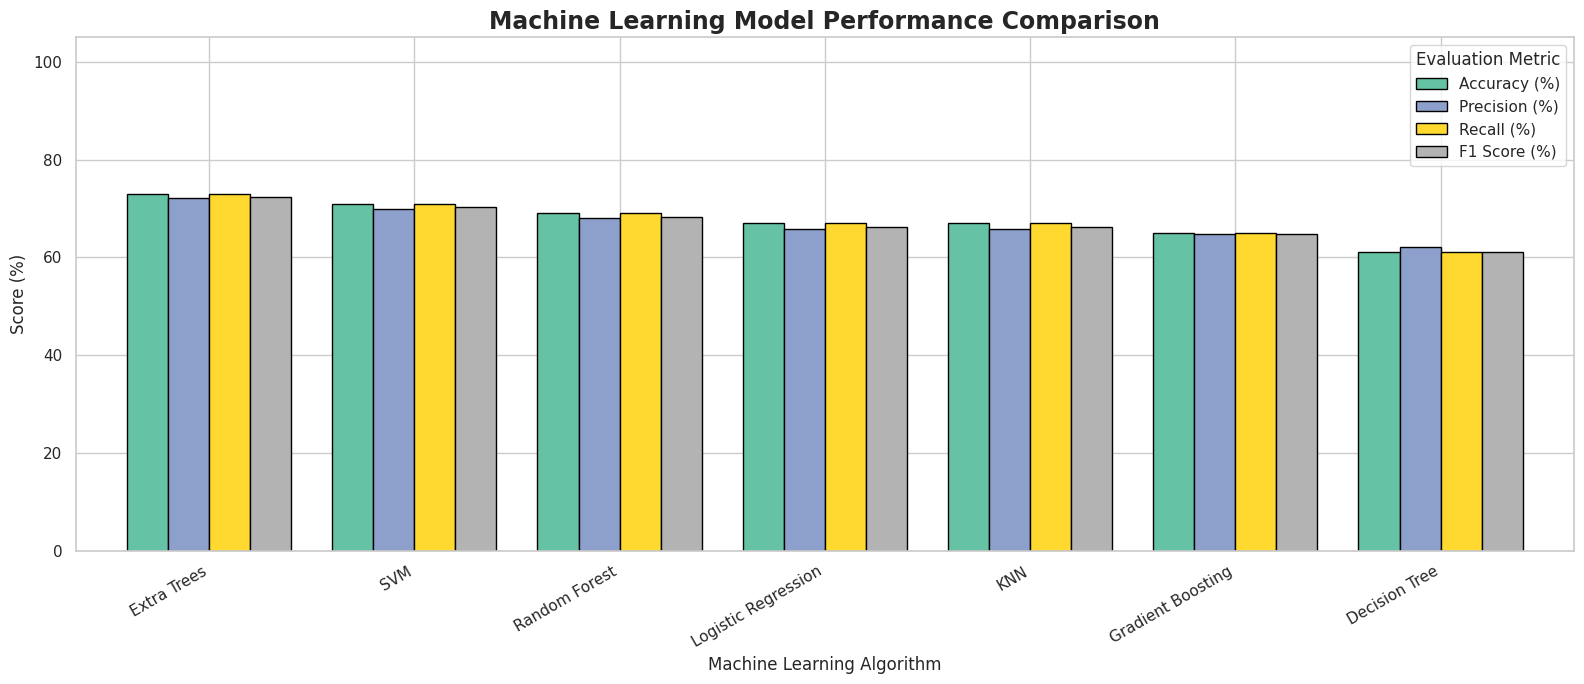

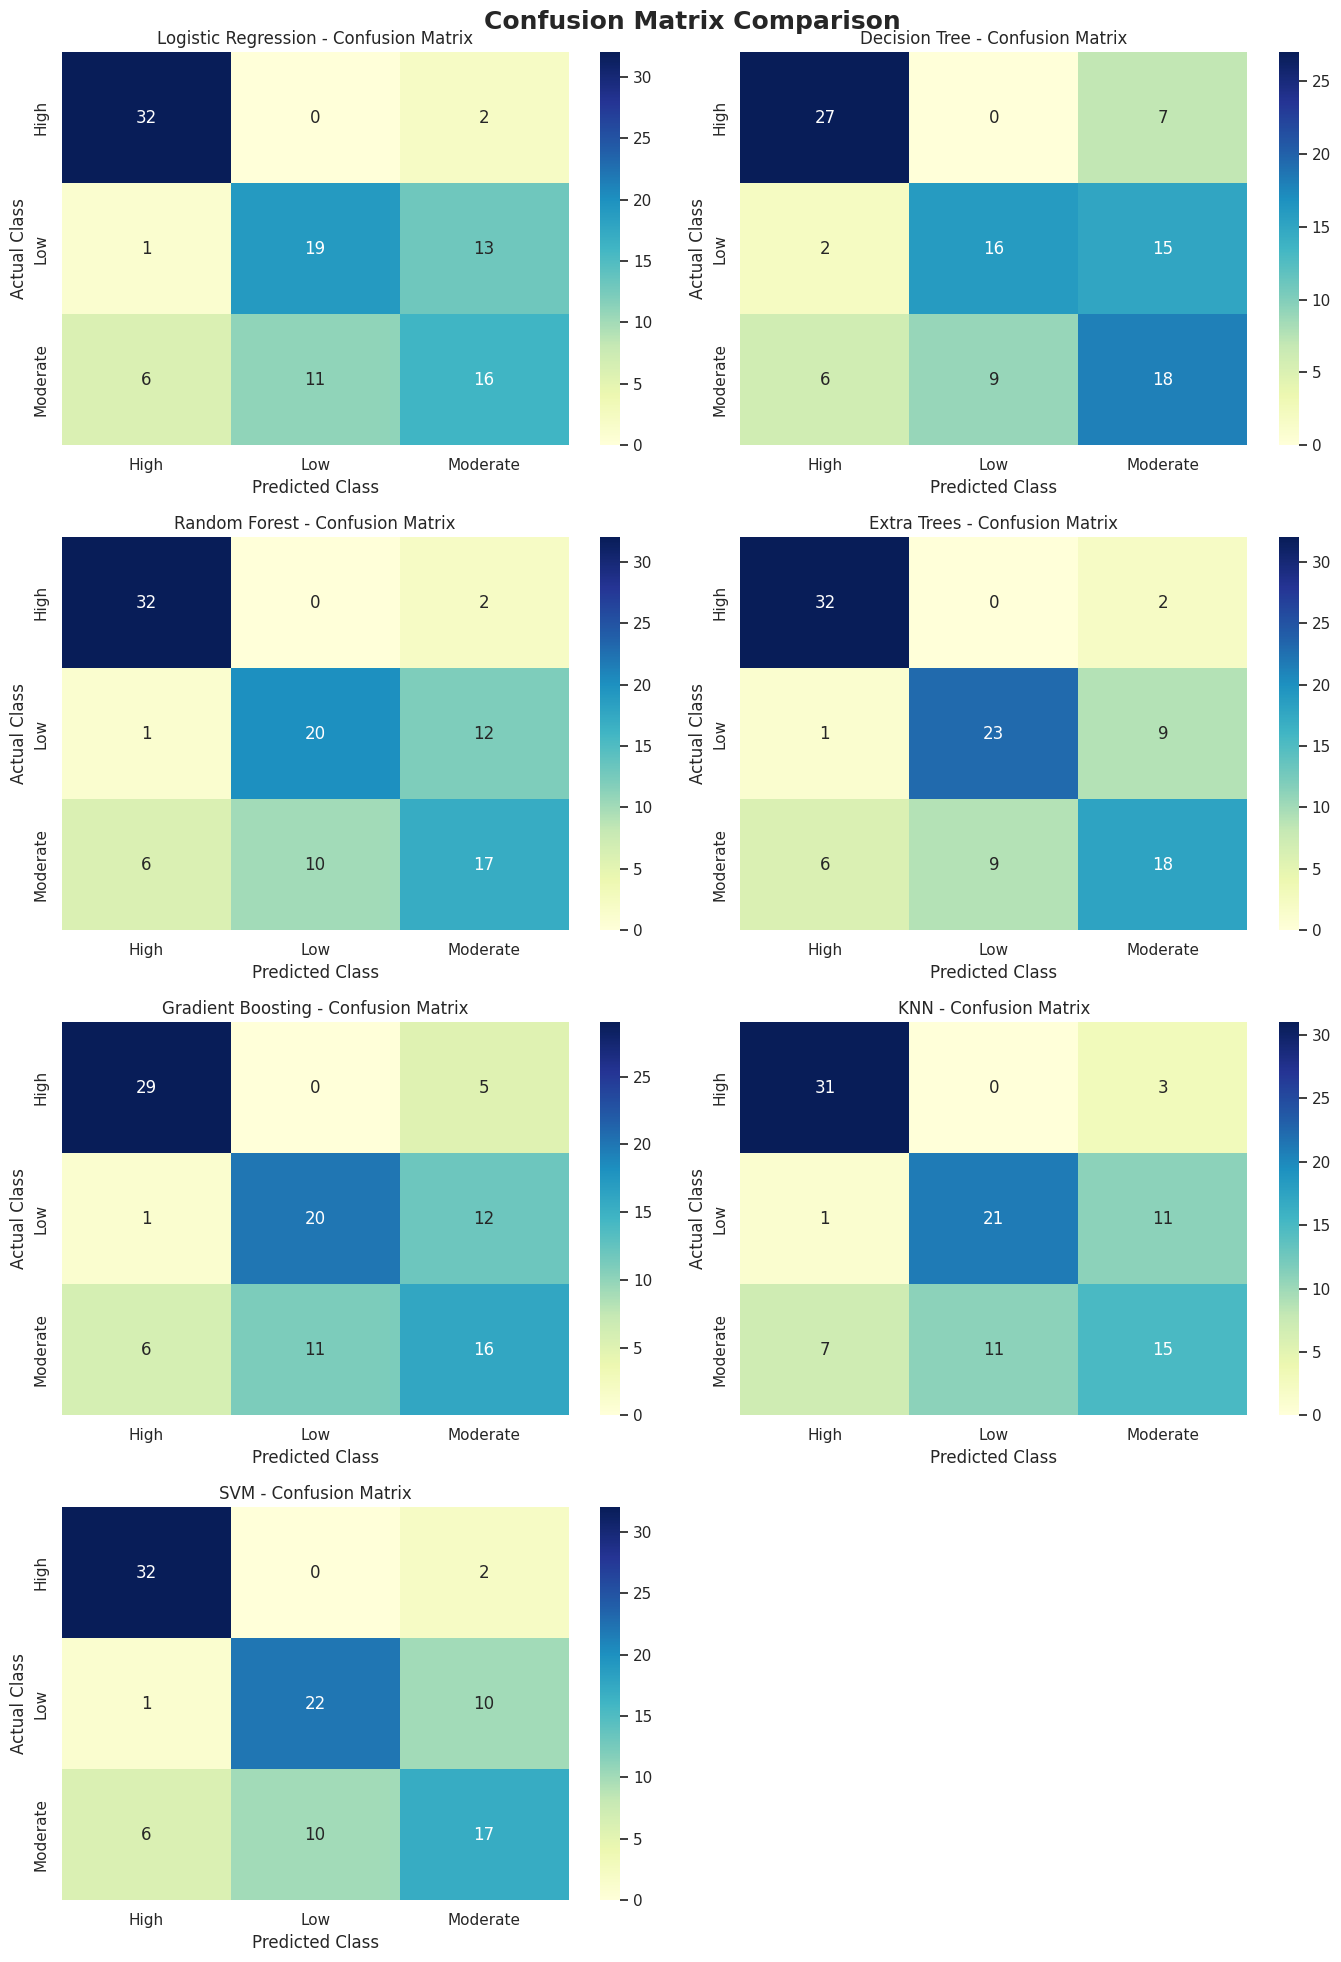

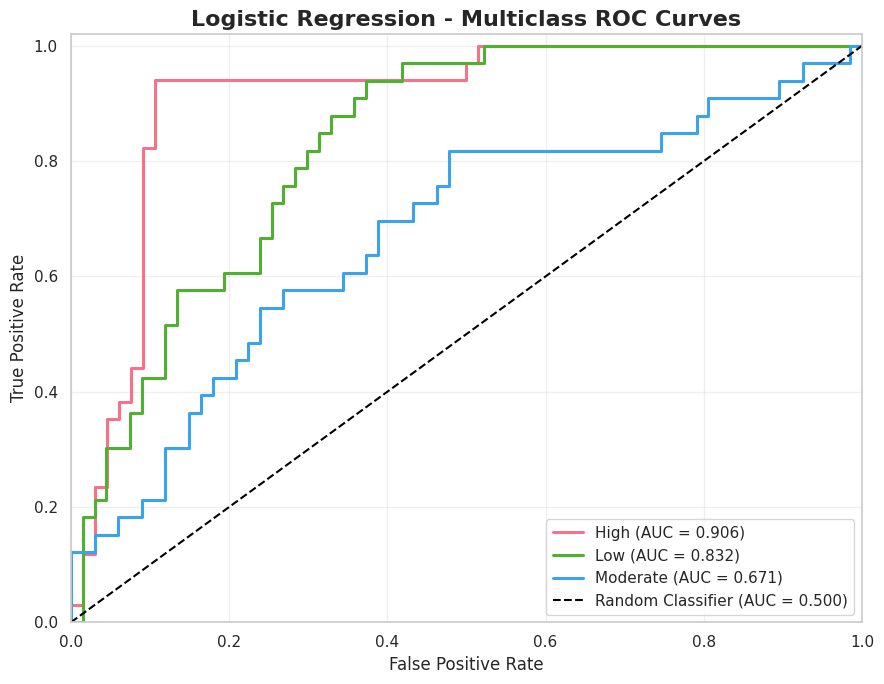

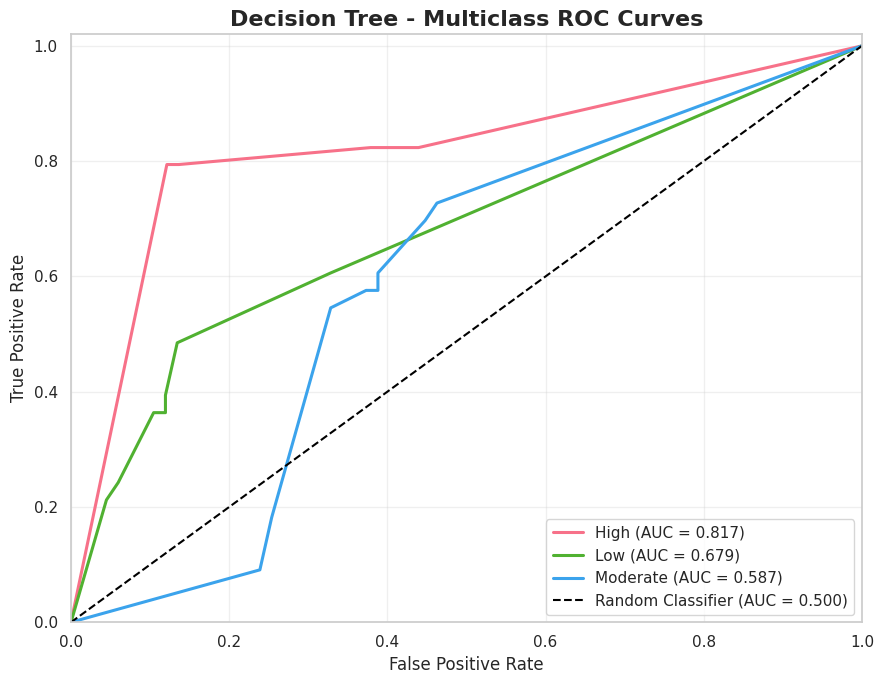

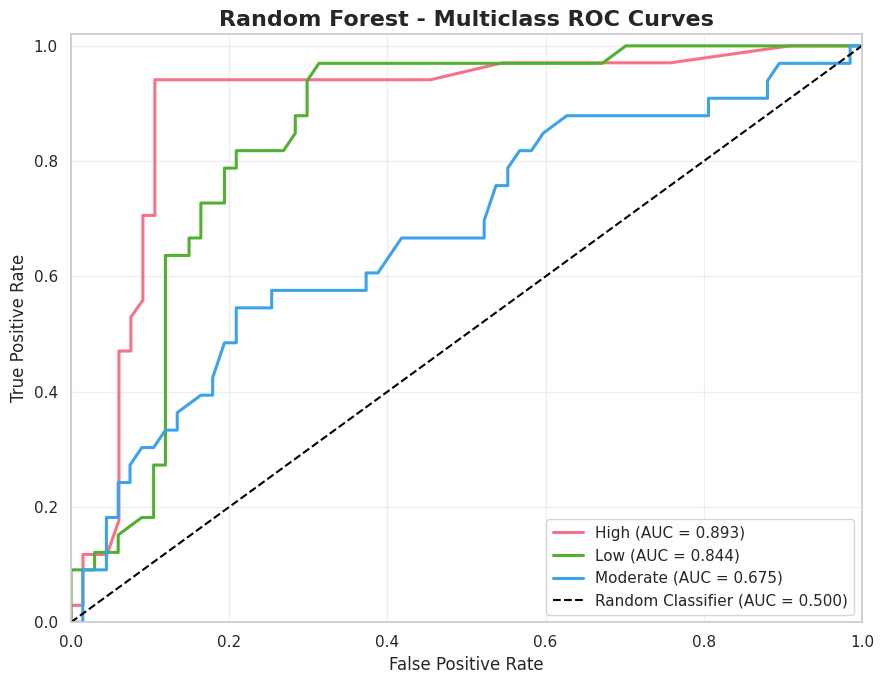

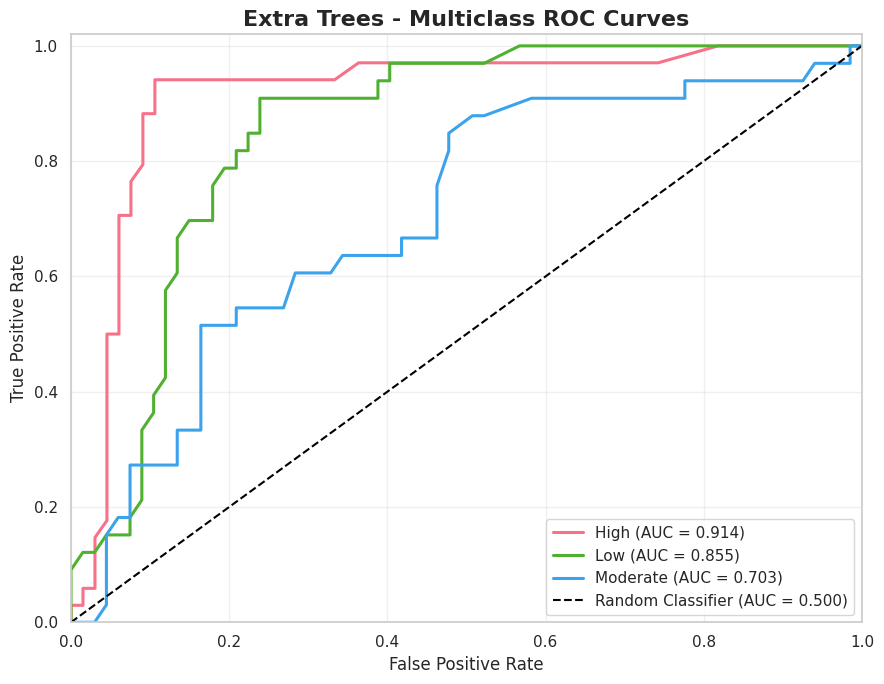

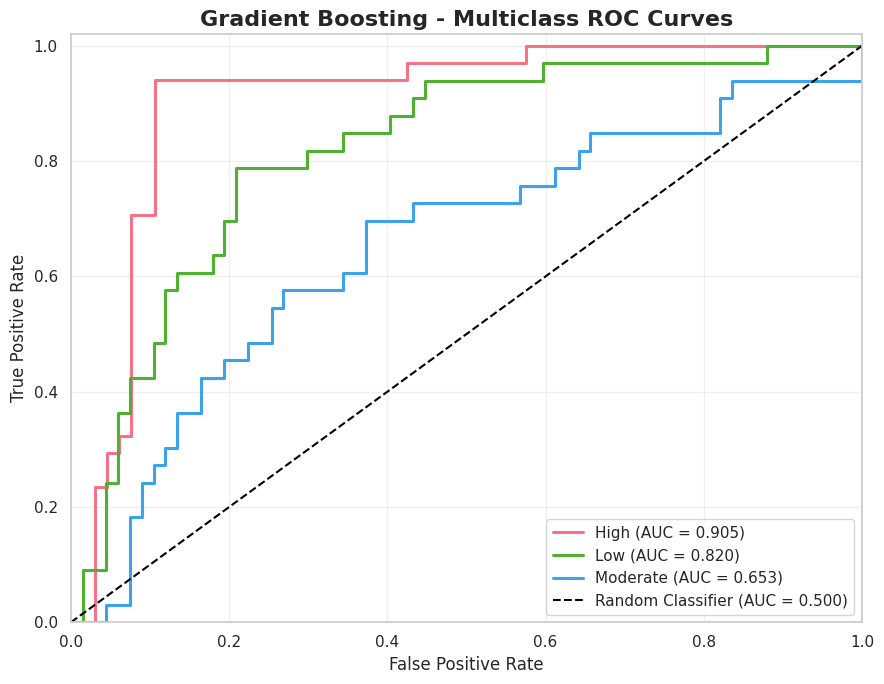

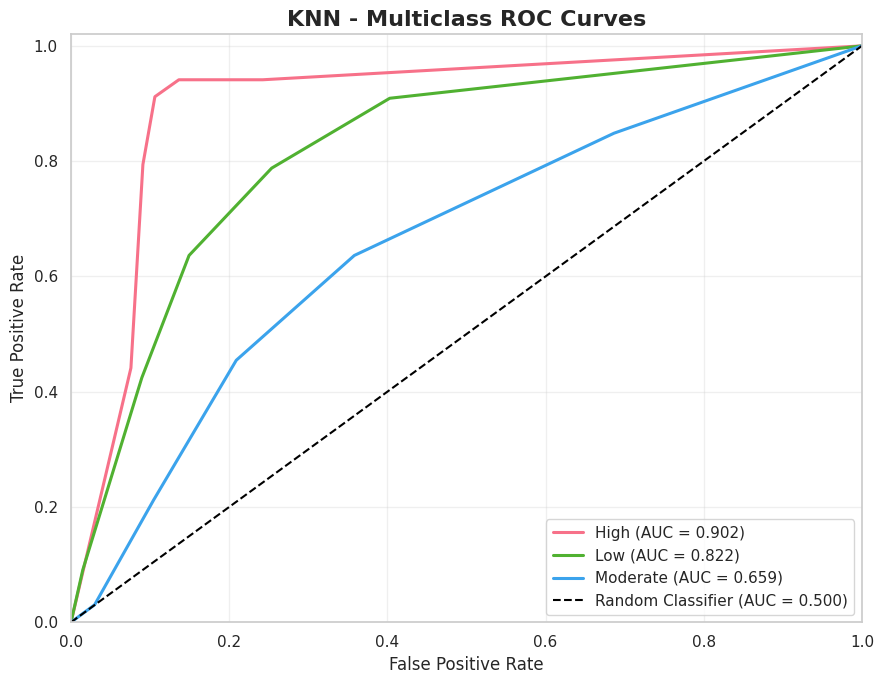

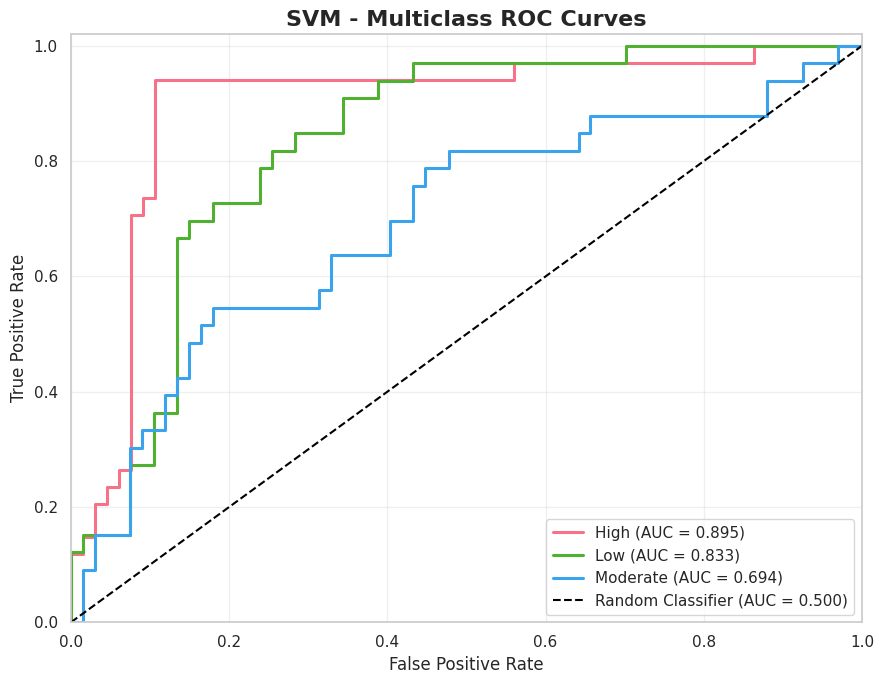

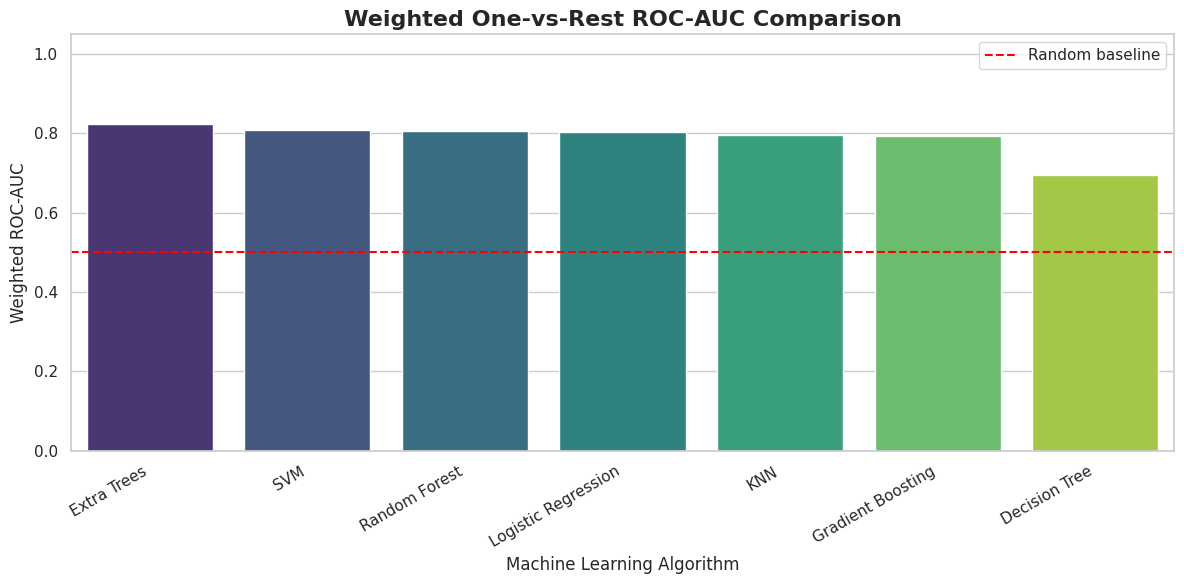


BEST MODEL BASED ON WEIGHTED F1 SCORE
Best model: Extra Trees
Weighted F1 Score: 72.32%
Accuracy: 73.00%

Final Classification Report:
              precision    recall  f1-score   support

        High       0.82      0.94      0.88        34
         Low       0.72      0.70      0.71        33
    Moderate       0.62      0.55      0.58        33

    accuracy                           0.73       100
   macro avg       0.72      0.73      0.72       100
weighted avg       0.72      0.73      0.72       100


Machine learning workflow completed.


In [14]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20

columns = [
    "PM2.5", "PM10", "NOx", "NO2", "SO2",
    "VOCs", "CO", "CO2", "CH4", "Temperature"
]

sns.set_theme(style="whitegrid", palette="Set2")

if "df" not in globals():
    raise NameError(
        "DataFrame 'df' not found. Load your dataset into df first."
    )

missing_columns = [c for c in columns if c not in df.columns]

if missing_columns:
    raise ValueError(
        f"These required columns are missing: {missing_columns}"
    )

data = df[columns].copy()

# ------------------------------------------------
# 2. DATA CLEANING
# ------------------------------------------------

for col in columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.replace([np.inf, -np.inf], np.nan)

# Remove rows where all 10 features are missing
data = data.dropna(how="all").reset_index(drop=True)

# Require enough usable observations
if len(data) < 20:
    raise ValueError(
        "At least 20 usable rows are recommended for this demonstration."
    )

# Remove columns that contain no usable values
empty_columns = data.columns[data.isna().all()].tolist()

if empty_columns:
    raise ValueError(
        f"These columns contain no numeric values: {empty_columns}"
    )

print("=" * 75)
print("AIR QUALITY MACHINE LEARNING")
print("=" * 75)

print("Dataset shape:", data.shape)
print("\nMissing values before imputation:")
print(data.isnull().sum())

# ------------------------------------------------
# 3. CREATE TARGET LABELS
# ------------------------------------------------
# All supplied columns are features, not a target.
# This illustrative target uses PM2.5 quantiles.
#
# Low       : PM2.5 at or below the 33rd percentile
# Moderate  : PM2.5 above 33rd and at or below 66th percentile
# High      : PM2.5 above the 66th percentile
#
# These are relative dataset categories, NOT official AQI labels.

if data["PM2.5"].notna().sum() < 10:
    raise ValueError("PM2.5 has too few valid observations.")

q1, q2 = data["PM2.5"].quantile([1/3, 2/3])

if q1 >= q2:
    raise ValueError(
        "PM2.5 values do not support three distinct quantile classes. "
        "Use an existing target column or define valid domain thresholds."
    )

# Exclude rows without the value needed to construct the target.
data = data.dropna(subset=["PM2.5"]).reset_index(drop=True)

data["Pollution_Level"] = pd.cut(
    data["PM2.5"],
    bins=[-np.inf, q1, q2, np.inf],
    labels=["Low", "Moderate", "High"],
    include_lowest=True
)

data = data.dropna(subset=["Pollution_Level"]).reset_index(drop=True)

print("\nTarget thresholds:")
print(f"Low: PM2.5 <= {q1:.4f}")
print(f"Moderate: {q1:.4f} < PM2.5 <= {q2:.4f}")
print(f"High: PM2.5 > {q2:.4f}")

print("\nTarget class distribution:")
print(data["Pollution_Level"].value_counts())

# ------------------------------------------------
# 4. FEATURES AND TARGET
# ------------------------------------------------

X = data[columns].copy()
y_text = data["Pollution_Level"].astype(str)

# IMPORTANT:
# PM2.5 defines the target above, so using PM2.5 as an input
# would leak the answer into the model. Remove it from X.
X = X.drop(columns=["PM2.5"])

print("\nFeature columns:", X.columns.tolist())
print("Target column: Pollution_Level")
print("Feature matrix shape:", X.shape)

# ------------------------------------------------
# 5. LABEL ENCODING
# ------------------------------------------------

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

print("\nLabel Encoding:")
for encoded_value, original_label in enumerate(label_encoder.classes_):
    print(f"{original_label} -> {encoded_value}")

# ------------------------------------------------
# 6. TRAIN-TEST SPLITTING
# ------------------------------------------------

class_counts = pd.Series(y).value_counts()

if class_counts.min() < 2:
    raise ValueError(
        "Every class needs at least 2 samples for stratified splitting."
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

# ------------------------------------------------
# 7. DEFINE ML ALGORITHMS
# ------------------------------------------------

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=8,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=RANDOM_STATE
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "SVM": SVC(
        kernel="rbf",
        probability=True,
        class_weight="balanced",
        random_state=RANDOM_STATE
    )
}

# ------------------------------------------------
# 8. PREPROCESSING PIPELINE
# ------------------------------------------------
# Imputation and scaling are fitted only on the training set.
# Pipelines help prevent preprocessing leakage.

results = []
trained_models = {}
predictions = {}
probabilities = {}
failed_models = {}

for name, algorithm in models.items():

    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", algorithm)
    ])

    try:
        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)

        trained_models[name] = pipeline
        predictions[name] = y_pred
        probabilities[name] = y_prob

        acc = accuracy_score(y_test, y_pred)
        prec = precision_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
        rec = recall_score(
            y_test, y_pred, average="weighted", zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred, average="weighted", zero_division=0
        )

        # Multiclass ROC-AUC using one-vs-rest
        try:
            auc_score = roc_auc_score(
                y_test,
                y_prob,
                labels=np.arange(len(label_encoder.classes_)),
                multi_class="ovr",
                average="weighted"
            )
        except ValueError:
            auc_score = np.nan

        results.append({
            "Model": name,
            "Accuracy (%)": acc * 100,
            "Precision (%)": prec * 100,
            "Recall (%)": rec * 100,
            "F1 Score (%)": f1 * 100,
            "ROC-AUC": auc_score
        })

        print(f"\n{'-' * 65}")
        print(name)
        print("-" * 65)
        print(f"Accuracy : {acc * 100:.2f}%")
        print(f"Precision: {prec * 100:.2f}%")
        print(f"Recall   : {rec * 100:.2f}%")
        print(f"F1 Score : {f1 * 100:.2f}%")
        print(
            f"ROC-AUC  : {auc_score:.4f}"
            if not np.isnan(auc_score)
            else "ROC-AUC  : unavailable"
        )

        print("\nClassification Report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(len(label_encoder.classes_)),
            target_names=label_encoder.classes_,
            zero_division=0
        ))

    except Exception as error:
        failed_models[name] = str(error)
        print(f"\n{name} failed: {error}")

if not results:
    raise RuntimeError(
        "All models failed. Check the dataset values and class distribution."
    )

# ------------------------------------------------
# 9. MODEL COMPARISON TABLE
# ------------------------------------------------

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score (%)",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 75)
print("MODEL COMPARISON")
print("=" * 75)

display(results_df.round(4))

if failed_models:
    print("\nModels that failed:")
    for model_name, error_message in failed_models.items():
        print(f"{model_name}: {error_message}")

# ------------------------------------------------
# 10. MODEL PERFORMANCE BAR CHART
# ------------------------------------------------

metrics = [
    "Accuracy (%)",
    "Precision (%)",
    "Recall (%)",
    "F1 Score (%)"
]

plot_results = results_df.set_index("Model")[metrics]

ax = plot_results.plot(
    kind="bar",
    figsize=(16, 7),
    colormap="Set2",
    edgecolor="black",
    width=0.8
)

ax.set_title(
    "Machine Learning Model Performance Comparison",
    fontsize=17,
    fontweight="bold"
)
ax.set_xlabel("Machine Learning Algorithm")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 105)
plt.xticks(rotation=30, ha="right")
plt.legend(title="Evaluation Metric")
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 11. CONFUSION MATRICES
# ------------------------------------------------

n_models = len(trained_models)
ncols = 2
nrows = int(np.ceil(n_models / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(14, 5 * nrows)
)

axes = np.array(axes).reshape(-1)
class_ids = np.arange(len(label_encoder.classes_))

for i, (name, y_pred) in enumerate(predictions.items()):

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_ids
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=axes[i]
    )

    axes[i].set_title(f"{name} - Confusion Matrix")
    axes[i].set_xlabel("Predicted Class")
    axes[i].set_ylabel("Actual Class")

for j in range(n_models, len(axes)):
    axes[j].set_visible(False)

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=18,
    fontweight="bold"
)
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 12. MULTICLASS ROC CURVES - ONE VS REST
# ------------------------------------------------
# Each curve evaluates one class against all remaining classes.
# AUC is calculated from held-out test data.

n_classes = len(label_encoder.classes_)

if n_classes >= 2:

    y_test_binary = label_binarize(
        y_test,
        classes=class_ids
    )

    colors = sns.color_palette(
        "husl", max(n_classes, 1)
    )

    # Individual ROC curves for every model
    for name, y_prob in probabilities.items():

        plt.figure(figsize=(9, 7))

        plotted_curve = False

        for class_index, class_name in enumerate(
            label_encoder.classes_
        ):

            # ROC needs both positive and negative examples
            if len(np.unique(y_test_binary[:, class_index])) < 2:
                continue

            fpr, tpr, thresholds = roc_curve(
                y_test_binary[:, class_index],
                y_prob[:, class_index]
            )

            class_auc = auc(fpr, tpr)

            plt.plot(
                fpr,
                tpr,
                color=colors[class_index],
                linewidth=2.2,
                label=f"{class_name} (AUC = {class_auc:.3f})"
            )

            plotted_curve = True

        plt.plot(
            [0, 1], [0, 1],
            linestyle="--",
            color="black",
            linewidth=1.5,
            label="Random Classifier (AUC = 0.500)"
        )

        if plotted_curve:
            plt.title(
                f"{name} - Multiclass ROC Curves",
                fontsize=16,
                fontweight="bold"
            )
            plt.xlabel("False Positive Rate")
            plt.ylabel("True Positive Rate")
            plt.xlim(0, 1)
            plt.ylim(0, 1.02)
            plt.legend(loc="lower right")
            plt.grid(alpha=0.3)
            plt.tight_layout()
            plt.show()
        else:
            plt.close()

    # ------------------------------------------------
    # 13. OVERALL ROC-AUC COMPARISON
    # ------------------------------------------------

    valid_auc = results_df.dropna(subset=["ROC-AUC"])

    if not valid_auc.empty:
        plt.figure(figsize=(12, 6))

        sns.barplot(
            data=valid_auc,
            x="Model",
            y="ROC-AUC",
            hue="Model",
            palette="viridis",
            legend=False
        )

        plt.axhline(
            0.5,
            color="red",
            linestyle="--",
            label="Random baseline"
        )

        plt.title(
            "Weighted One-vs-Rest ROC-AUC Comparison",
            fontsize=16,
            fontweight="bold"
        )
        plt.xlabel("Machine Learning Algorithm")
        plt.ylabel("Weighted ROC-AUC")
        plt.ylim(0, 1.05)
        plt.xticks(rotation=30, ha="right")
        plt.legend()
        plt.tight_layout()
        plt.show()

# ------------------------------------------------
# 14. BEST MODEL SUMMARY
# ------------------------------------------------

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\n" + "=" * 75)
print("BEST MODEL BASED ON WEIGHTED F1 SCORE")
print("=" * 75)

print("Best model:", best_model_name)
print(
    "Weighted F1 Score:",
    f"{results_df.iloc[0]['F1 Score (%)']:.2f}%"
)
print(
    "Accuracy:",
    f"{results_df.iloc[0]['Accuracy (%)']:.2f}%"
)

best_predictions = predictions[best_model_name]

print("\nFinal Classification Report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=class_ids,
    target_names=label_encoder.classes_,
    zero_division=0
))

print("\nMachine learning workflow completed.")


## Thank you..pls upvote!!!!!!!